# EDA v1 — Phân khúc khách hàng bằng RFM và hành vi mua hàng

**Ngô Nguyên — MSSV 3124411191 — Nhóm 15 — Form 1.**

## 1. Giới thiệu bài toán, dữ liệu và câu hỏi EDA

Notebook khám phá tệp `data/raw/online_retail_II.xlsx` trong repository để chuẩn bị
cho phân khúc khách hàng bằng RFM và hành vi mua. Đơn vị nguồn là **dòng mặt hàng/bút toán**;
đơn vị phân cụm dự kiến là **khách hàng**. Số dòng, số mã hóa đơn duy nhất và số khách hàng
được báo cáo riêng. Đây là EDA lịch sử; chưa tạo tập đặc trưng chính thức, gán nhãn VIP,
huấn luyện mô hình hoặc dự đoán giá trị tương lai.

Nguồn và từ điển: [Chen, D. (2012), Online Retail II — UCI](https://archive.ics.uci.edu/dataset/502/online+retail+ii),
[DOI 10.24432/C5CG6D](https://doi.org/10.24432/C5CG6D).
Theo UCI, đơn giá tính bằng GBP, mã hóa đơn bắt đầu bằng `C` biểu thị hủy.
Các số đếm, bảng và nhận xét bên dưới **được tính từ workbook cục bộ**,
không thay bằng thống kê công bố. Kết quả trong notebook là lần chạy trên toàn bộ dữ liệu thực tế;
`head()` chỉ là bảng xem trước, không phải mẫu tính thống kê.

**Câu hỏi EDA:**

1. Các sheet có cùng cấu trúc, phạm vi thời gian và kiểu dữ liệu để gộp không?
2. Thiếu, trùng, chồng lấn, dấu hiệu hủy và lượng/giá không dương ảnh hưởng gì đến RFM?
3. Quantity, Price, giá trị dòng, Country và dấu hiệu tiền tố C phân bố thế nào?
4. Quantity liên hệ với Price ra sao; cơ cấu chứng từ C và giá trị dòng khác nhau thế nào theo Country?
5. Số hóa đơn theo **Country × tháng** thay đổi thế nào trong cửa sổ quan sát?
6. Thời điểm ghi nhận, số hóa đơn và giá trị đại số giao dịch cho thấy điều gì?
7. Với điều kiện khảo sát tạm thời, khách hàng có bao nhiêu hóa đơn được quan sát và mức giá trị thế nào?

**Quy tắc chung:** đọc tất cả sheet, gộp trong bộ nhớ sau kiểm tra tương thích;
giữ nguyên dữ liệu thô, dòng thiếu, hủy, âm, trùng và ngoại lai. Các phép lọc để khảo sát
được nêu ngay tại phần tương ứng. Không lấy mẫu cho biểu đồ; mọi hình dùng toàn bộ
quan sát thuộc phạm vi đã ghi hoặc bảng tổng hợp của phạm vi đó.
Hình hiển thị trong notebook và được lưu cùng nội dung vào `01_eda/figures/*.png`.

## 2. Overview

### 2.1. Quy ước và môi trường

**Câu hỏi:** dữ liệu được đọc ở đâu, với môi trường nào và đơn vị phân tích nào?

- Một dòng không phải một hóa đơn hoàn chỉnh. Một khách hàng có thể có nhiều hóa đơn.
- Invoice, StockCode và Customer ID là **mã định danh**, dù có thể được Excel lưu bằng số.
- Mã khách hàng hợp lệ về hình thức: số hữu hạn, nguyên dương, có 5 chữ số theo từ điển UCI;
  quy tắc này không xác nhận danh tính ngoài hệ thống.
- Giữ thời gian nguồn vì workbook không có thông tin múi giờ.
- `LineValue = Quantity × Price` là giá trị đại số của dòng (GBP), chưa phải doanh thu
  đã làm sạch, lợi nhuận hoặc giá trị vòng đời. Chính sách hoàn/hủy và ngoại lai chưa chốt.

**Phạm vi/cách tính:** thư viện đã có, đường dẫn tương đối theo repository;
chỉ đọc nguồn và ghi hình vào `figures/`.

In [1]:
from pathlib import Path
import hashlib
import io
import platform
from importlib.metadata import version

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter
from IPython.display import display, Markdown, Image

pd.set_option('display.max_columns', 14)
pd.set_option('display.max_rows', 45)
pd.set_option('display.float_format', lambda value: f'{value:,.3f}')
plt.rcParams.update({
    'font.family': 'DejaVu Sans', 'font.size': 11,
    'axes.titlesize': 13, 'axes.labelsize': 11,
    'figure.dpi': 110, 'savefig.dpi': 150,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': False, 'figure.facecolor': 'white', 'axes.facecolor': 'white',
    'savefig.facecolor': 'white',
})
BLUE, GOLD, GRAY = '#245B84', '#B46A11', '#5A6068'

def vn_int(value):
    return f'{int(value):,}'.replace(',', '.')

def note(text):
    display(Markdown('**Nhận xét.** ' + text))

def show_table(frame, formats=None):
    display(frame.style.format(formats or {}, na_rep='—').hide(axis='index'))

def sha256(path):
    digest = hashlib.sha256()
    with path.open('rb') as stream:
        for chunk in iter(lambda: stream.read(1024 * 1024), b''):
            digest.update(chunk)
    return digest.hexdigest()

def find_project(start):
    for parent in [start, *start.parents]:
        for candidate in (parent, parent / 'project'):
            if (candidate / 'data/raw/online_retail_II.xlsx').is_file() and (candidate / 'requirements.txt').is_file():
                return candidate
    raise FileNotFoundError('Mở notebook từ repository hoặc project/notebooks/01_eda; cần data/raw/online_retail_II.xlsx.')

PROJECT_DIR = find_project(Path.cwd().resolve())
DATA_PATH = PROJECT_DIR / 'data/raw/online_retail_II.xlsx'
source_hash_before = sha256(DATA_PATH)
FIGURES_DIR = PROJECT_DIR / 'notebooks/01_eda/figures'
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
figure_registry = {}

def show_figure(fig, filename):
    # Cùng một chuỗi byte PNG được ghi ra đĩa và hiển thị, tránh hai bản render khác nhau.
    if Path(filename).name != filename or not filename.endswith('.png'):
        raise ValueError('Tên hình phải là tên tệp PNG trong figures/.')
    if filename in figure_registry:
        raise ValueError(f'Tên hình bị dùng lặp trong một lần chạy: {filename}')
    buffer = io.BytesIO()
    fig.savefig(buffer, format='png', dpi=150, bbox_inches='tight',
                metadata={'Source': 'data/raw/online_retail_II.xlsx', 'SourceSHA256': source_hash_before})
    png = buffer.getvalue()
    target = FIGURES_DIR / filename
    target.write_bytes(png)
    digest = hashlib.sha256(png).hexdigest()
    figure_registry[filename] = {'sha256': digest, 'bytes': len(png)}
    display(Image(data=png, width=min(1200, round(fig.get_figwidth() * 110))),
            metadata={'figure_file': 'figures/' + filename, 'figure_sha256': digest})
    plt.close(fig)
environment = {'Python': platform.python_version(), **{
    package: version(package) for package in
    ['numpy', 'pandas', 'matplotlib', 'openpyxl', 'nbformat', 'nbclient', 'ipykernel']
}}
show_table(pd.DataFrame(environment.items(), columns=['Thành phần', 'Phiên bản']))
note('Đường dẫn được tìm từ thư mục hiện tại và các thư mục cha; không chứa đường dẫn tuyệt đối riêng của máy. '
     'Notebook đọc Excel, phân tích trong bộ nhớ và chỉ ghi các hình vào figures/. Phiên bản ở bảng trên là môi trường thực sự chạy.')

Thành phần,Phiên bản
Python,3.12.15
numpy,2.5.4
pandas,3.1.0
matplotlib,3.11.2
openpyxl,3.1.5
nbformat,5.11.1
nbclient,0.11.0
ipykernel,7.4.0


**Nhận xét.** Đường dẫn được tìm từ thư mục hiện tại và các thư mục cha; không chứa đường dẫn tuyệt đối riêng của máy. Notebook đọc Excel, phân tích trong bộ nhớ và chỉ ghi các hình vào figures/. Phiên bản ở bảng trên là môi trường thực sự chạy.

### 2.2. Sheet, tên cột, kiểu dữ liệu và thời gian

**Câu hỏi:** các sheet có tương thích để gộp và có thời gian chồng lấn không?

**Phạm vi/cách tính:** kiểm tra từng sheet, tên/cấu trúc cột, dtype, số dòng,
ngày đầu/cuối, ngày thiếu và lỗi phân tích. Dừng nếu cấu trúc hoặc kiểu dữ liệu khác nhau.
`errors='coerce'` chỉ dùng trên bản sao để phát hiện lỗi; không sửa Excel gốc.

In [2]:
with pd.ExcelFile(DATA_PATH, engine='openpyxl') as workbook:
    sheet_names = workbook.sheet_names
    sheets = {name: pd.read_excel(workbook, sheet_name=name) for name in sheet_names}

original_columns = list(sheets[sheet_names[0]].columns)
required_columns = {'Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country'}
if set(original_columns) != required_columns:
    raise ValueError(f'Cấu trúc nguồn cần được xem xét lại: {original_columns}')
if any(set(part.columns) != set(original_columns) for part in sheets.values()):
    raise ValueError('Các sheet khác cấu trúc; không tự động bỏ cột hoặc sheet. Cần rà soát trước khi gộp.')

sheet_records = []
dtype_records = []
for name, part in sheets.items():
    dates = pd.to_datetime(part['InvoiceDate'], errors='coerce')
    sheet_records.append({
        'Sheet': name, 'Số dòng': len(part), 'Số cột': part.shape[1],
        'Từ': dates.min(), 'Đến': dates.max(),
        'Ngày thiếu': int(part['InvoiceDate'].isna().sum()),
        'Ngày lỗi khác thiếu': int((part['InvoiceDate'].notna() & dates.isna()).sum()),
    })
    dtype_records.extend({'Sheet': name, 'Cột': column, 'Kiểu dữ liệu': str(part[column].dtype)} for column in original_columns)
sheet_profile = pd.DataFrame(sheet_records)
show_table(sheet_profile)
note('Đã đọc các sheet: ' + ', '.join(sheet_names) + '. Mọi sheet có cùng tập cột; thứ tự được căn theo sheet đầu. '
     'Khoảng thời gian có thể chồng lấn: phần trùng giữa sheet được kiểm tra riêng ở mục 3, chưa loại bỏ.')

Sheet,Số dòng,Số cột,Từ,Đến,Ngày thiếu,Ngày lỗi khác thiếu
Year 2009-2010,525461,8,2009-12-01 07:45:00,2010-12-09 20:01:00,0,0
Year 2010-2011,541910,8,2010-12-01 08:26:00,2011-12-09 12:50:00,0,0


**Nhận xét.** Đã đọc các sheet: Year 2009-2010, Year 2010-2011. Mọi sheet có cùng tập cột; thứ tự được căn theo sheet đầu. Khoảng thời gian có thể chồng lấn: phần trùng giữa sheet được kiểm tra riêng ở mục 3, chưa loại bỏ.

In [3]:
sheet_dtypes = pd.DataFrame(dtype_records).pivot(index='Cột', columns='Sheet', values='Kiểu dữ liệu').reset_index()
show_table(sheet_dtypes)
dtype_compatible = all(sheets[name][column].dtype == sheets[sheet_names[0]][column].dtype
                       for name in sheet_names for column in original_columns)
if not dtype_compatible:
    raise TypeError('Kiểu dữ liệu giữa sheet khác nhau; cần quyết định chuyển kiểu trước khi gộp.')
note('Kiểu dữ liệu suy luận tương thích giữa các sheet. Các mã có thể gồm số và chữ nên sẽ có cột định danh phân tích riêng; '
     'không tính trung bình mã khách hàng hoặc mã hóa đơn.')

raw = pd.concat([sheets[name].loc[:, original_columns] for name in sheet_names], ignore_index=True)
source_sheet = pd.concat([pd.Series(name, index=range(len(sheets[name]))) for name in sheet_names], ignore_index=True)
assert len(raw) == sum(len(part) for part in sheets.values())
display(raw.head(5))
note(f'Bảng xem trước giữ tên cột của Excel. Dữ liệu gộp có {vn_int(len(raw))} dòng và {len(original_columns)} cột nguồn. '
     'Tên sheet được giữ trong biến riêng, không làm thay đổi định nghĩa dòng trùng trên 8 cột nguồn.')

Cột,Year 2009-2010,Year 2010-2011
Country,str,str
Customer ID,float64,float64
Description,object,object
Invoice,object,object
InvoiceDate,datetime64[us],datetime64[us]
Price,float64,float64
Quantity,int64,int64
StockCode,object,object


**Nhận xét.** Kiểu dữ liệu suy luận tương thích giữa các sheet. Các mã có thể gồm số và chữ nên sẽ có cột định danh phân tích riêng; không tính trung bình mã khách hàng hoặc mã hóa đơn.

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.950,"13,085.000",United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.750,"13,085.000",United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.750,"13,085.000",United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.100,"13,085.000",United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.250,"13,085.000",United Kingdom


**Nhận xét.** Bảng xem trước giữ tên cột của Excel. Dữ liệu gộp có 1.067.371 dòng và 8 cột nguồn. Tên sheet được giữ trong biến riêng, không làm thay đổi định nghĩa dòng trùng trên 8 cột nguồn.

### 2.3. Xem nhanh bằng API pandas

**Câu hỏi:** dữ liệu sau gộp trông thế nào, có bao nhiêu dòng/cột và cột nào thiếu?

**Phạm vi/cách tính:** `data` tham chiếu bảng `raw` gồm toàn bộ 8 cột nguồn, không làm sạch.
`head()` chỉ hiển thị 5 dòng đầu. `info(show_counts=True)` báo số khác thiếu trên toàn bộ bảng.
`describe()` là kiểm tra API ban đầu: **Customer ID vẫn là định danh**, không diễn giải
trung bình, độ lệch chuẩn hay phân vị của mã. Thống kê biến đo lường được tách ở mục 4.

In [4]:
data = raw
display(data.head())
print('data.shape (số dòng, số cột nguồn):', data.shape)
data.info(show_counts=True, memory_usage='deep')
display(data.describe().T)
note(f'Bảng nguồn có {vn_int(data.shape[0])} dòng và {data.shape[1]} cột. '
     'dtype chỉ là cách lưu trữ; Customer ID không trở thành biến đo lường vì được lưu bằng float. '
     'Khoảng ngày trong describe() cần đọc cùng kiểm kê từng sheet ở trên.')

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.950,"13,085.000",United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.750,"13,085.000",United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.750,"13,085.000",United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.100,"13,085.000",United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.250,"13,085.000",United Kingdom


data.shape (số dòng, số cột nguồn): (1067371, 8)


<class 'pandas.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype         
---  ------       --------------    -----         
 0   Invoice      1067371 non-null  object        
 1   StockCode    1067371 non-null  object        
 2   Description  1062989 non-null  object        
 3   Quantity     1067371 non-null  int64         
 4   InvoiceDate  1067371 non-null  datetime64[us]
 5   Price        1067371 non-null  float64       
 6   Customer ID  824364 non-null   float64       
 7   Country      1067371 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 207.3 MB


,count,mean,min,25%,50%,75%,max,std
Quantity,"1,067,371.000",9.939,"-80,995.000",1.000,3.000,10.000,"80,995.000",172.706
InvoiceDate,1067371,2011-01-02 21:13:55.394029,2009-12-01 07:45:00,2010-07-09 09:46:00,2010-12-07 15:28:00,2011-07-22 10:23:00,2011-12-09 12:50:00,NaN
Price,"1,067,371.000",4.649,"-53,594.360",1.250,2.100,4.150,"38,970.000",123.553
Customer ID,"824,364.000","15,324.639","12,346.000","13,975.000","15,255.000","16,797.000","18,287.000","1,697.464"


**Nhận xét.** Bảng nguồn có 1.067.371 dòng và 8 cột. dtype chỉ là cách lưu trữ; Customer ID không trở thành biến đo lường vì được lưu bằng float. Khoảng ngày trong describe() cần đọc cùng kiểm kê từng sheet ở trên.

### 2.4. Vai trò biến và phạm vi quan sát

**Câu hỏi:** đâu là biến số, phân loại, thời gian và định danh; đơn vị đếm là gì?

**Phạm vi/cách tính:** tạo bản sao `eda`, chuẩn hóa khoảng trắng/mã để đếm và kiểm tra;
giữ tên sheet ở biến riêng. Mã hàng có thể bao gồm dịch vụ/điều chỉnh,
không mặc định mọi StockCode là sản phẩm hàng hóa.

In [5]:
def normalized_identifier(series):
    return series.astype('string').str.strip().str.replace(r'(?<=\d)\.0$', '', regex=True).replace('', pd.NA)

eda = raw.copy()
eda['InvoiceKey'] = normalized_identifier(raw['Invoice'])
eda['StockKey'] = normalized_identifier(raw['StockCode'])
eda['CountryKey'] = raw['Country'].astype('string').str.strip().replace('', pd.NA)
eda['InvoiceDateParsed'] = pd.to_datetime(raw['InvoiceDate'], errors='coerce')
for column in ['Quantity', 'Price', 'Customer ID']:
    eda[column] = pd.to_numeric(raw[column], errors='coerce')
customer = eda['Customer ID']
valid_customer = customer.notna() & np.isfinite(customer) & customer.between(10000, 99999) & customer.mod(1).eq(0)
cancelled = eda['InvoiceKey'].str.upper().str.startswith('C', na=False)
eda['LineValue'] = eda['Quantity'] * eda['Price']
n_rows = len(raw)
n_invoices = int(eda['InvoiceKey'].nunique())
n_customers = int(customer[valid_customer].nunique())
n_countries = int(eda['CountryKey'].nunique())
n_stockcodes = int(eda['StockKey'].nunique())
date_min, date_max = eda['InvoiceDateParsed'].min(), eda['InvoiceDateParsed'].max()
overview = pd.DataFrame([
    ('Dòng giao dịch thô', n_rows), ('Cột nguồn', len(original_columns)),
    ('Khách hàng có mã hợp lệ về hình thức', n_customers),
    ('Dòng có mã khách hàng hợp lệ về hình thức', int(valid_customer.sum())),
    ('Mã hóa đơn duy nhất (gồm hủy/điều chỉnh)', n_invoices),
    ('Nhãn quốc gia duy nhất', n_countries), ('Mã hàng duy nhất (chưa phân loại dịch vụ)', n_stockcodes),
    ('Thời điểm đầu', str(date_min)), ('Thời điểm cuối', str(date_max)),
], columns=['Chỉ tiêu', 'Giá trị'])
show_table(overview)
show_table(pd.DataFrame({'Cột nguồn': raw.columns, 'Kiểu dữ liệu sau gộp': raw.dtypes.astype(str).values}))
note(f'{vn_int(n_rows)} dòng không phải {vn_int(n_rows)} lần mua: có {vn_int(n_invoices)} mã hóa đơn và '
     f'{vn_int(n_customers)} khách hàng nhận diện được theo quy tắc hình thức. '
     f'Các thống kê dùng toàn bộ sheet, từ {date_min:%d/%m/%Y %H:%M} đến {date_max:%d/%m/%Y %H:%M}; '
     'số quốc gia là số nhãn trong nguồn, chưa chuẩn hóa địa lý.')

Chỉ tiêu,Giá trị
Dòng giao dịch thô,1067371
Cột nguồn,8
Khách hàng có mã hợp lệ về hình thức,5942
Dòng có mã khách hàng hợp lệ về hình thức,824364
Mã hóa đơn duy nhất (gồm hủy/điều chỉnh),53628
Nhãn quốc gia duy nhất,43
Mã hàng duy nhất (chưa phân loại dịch vụ),5304
Thời điểm đầu,2009-12-01 07:45:00
Thời điểm cuối,2011-12-09 12:50:00


Cột nguồn,Kiểu dữ liệu sau gộp
Invoice,object
StockCode,object
Description,object
Quantity,int64
InvoiceDate,datetime64[us]
Price,float64
Customer ID,float64
Country,str


**Nhận xét.** 1.067.371 dòng không phải 1.067.371 lần mua: có 53.628 mã hóa đơn và 5.942 khách hàng nhận diện được theo quy tắc hình thức. Các thống kê dùng toàn bộ sheet, từ 01/12/2009 07:45 đến 09/12/2011 12:50; số quốc gia là số nhãn trong nguồn, chưa chuẩn hóa địa lý.

In [6]:
variable_roles = pd.DataFrame([
    ('Invoice', 'Mã định danh chứng từ', 'Danh nghĩa; dùng nunique, kiểm tra tiền tố C'),
    ('StockCode', 'Mã định danh mặt hàng/bút toán', 'Danh nghĩa; có mã dịch vụ, không tính trung bình'),
    ('Description', 'Phân loại/văn bản mô tả', 'Tên/mô tả, có thể thiếu hoặc không nhất quán'),
    ('Quantity', 'Số — rời rạc', 'Đơn vị/dòng; dấu âm cần xét nghiệp vụ'),
    ('InvoiceDate', 'Thời gian', 'Ngày giờ nguồn; không có múi giờ'),
    ('Price', 'Số — liên tục', 'GBP/đơn vị; kiểm tra 0/âm và cực trị'),
    ('Customer ID', 'Mã định danh khách hàng', 'Danh nghĩa dù dtype là số; có thể thiếu'),
    ('Country', 'Phân loại danh nghĩa', 'Nhãn trong nguồn, chưa xác minh địa lý'),
    ('LineValue (tạo cho EDA)', 'Số — liên tục', 'Quantity × Price, GBP/dòng; giữ cả dấu âm'),
], columns=['Biến', 'Vai trò phân tích', 'Diễn giải/đơn vị'])
show_table(variable_roles)
note('Các phép đếm hóa đơn dùng InvoiceKey duy nhất; khách hàng dùng Customer ID hợp lệ về hình thức. '
     'Country và dấu hiệu C là biến phân loại. Không đưa các mã vào tương quan số.')

Biến,Vai trò phân tích,Diễn giải/đơn vị
Invoice,Mã định danh chứng từ,"Danh nghĩa; dùng nunique, kiểm tra tiền tố C"
StockCode,Mã định danh mặt hàng/bút toán,"Danh nghĩa; có mã dịch vụ, không tính trung bình"
Description,Phân loại/văn bản mô tả,"Tên/mô tả, có thể thiếu hoặc không nhất quán"
Quantity,Số — rời rạc,Đơn vị/dòng; dấu âm cần xét nghiệp vụ
InvoiceDate,Thời gian,Ngày giờ nguồn; không có múi giờ
Price,Số — liên tục,GBP/đơn vị; kiểm tra 0/âm và cực trị
Customer ID,Mã định danh khách hàng,Danh nghĩa dù dtype là số; có thể thiếu
Country,Phân loại danh nghĩa,"Nhãn trong nguồn, chưa xác minh địa lý"
LineValue (tạo cho EDA),Số — liên tục,"Quantity × Price, GBP/dòng; giữ cả dấu âm"


**Nhận xét.** Các phép đếm hóa đơn dùng InvoiceKey duy nhất; khách hàng dùng Customer ID hợp lệ về hình thức. Country và dấu hiệu C là biến phân loại. Không đưa các mã vào tương quan số.

## 3. Chất lượng dữ liệu và rủi ro cho RFM

### 3.1. Thiếu và lỗi chuyển kiểu

**Câu hỏi:** thiếu/không chuyển được kiểu ở đâu, có khác nhau giữa sheet không?

**Phạm vi/cách tính:** mẫu số tỷ lệ là toàn bộ dòng thô của workbook hoặc từng sheet.
Tách thiếu thật, chuỗi rỗng sau trim và lỗi chuyển số/ngày; không tự điền giá trị.

In [7]:
missing = pd.DataFrame({
    'Cột': original_columns,
    'Số giá trị thiếu': raw.isna().sum().values,
    'Tỷ lệ thiếu (%)': raw.isna().mean().mul(100).values,
    'Chuỗi rỗng sau trim': [int(raw[col].astype('string').str.strip().eq('').fillna(False).sum()) for col in original_columns],
}).sort_values('Số giá trị thiếu', ascending=False)
show_table(missing, {'Tỷ lệ thiếu (%)': '{:.3f}'})
conversion_errors = {col: int((raw[col].notna() & eda[col].isna()).sum()) for col in ['Quantity', 'Price', 'Customer ID']}
date_missing = int(raw['InvoiceDate'].isna().sum())
date_invalid = int((raw['InvoiceDate'].notna() & eda['InvoiceDateParsed'].isna()).sum())
customer_missing = int(raw['Customer ID'].isna().sum())
customer_invalid_nonmissing = int((raw['Customer ID'].notna() & ~valid_customer).sum())
note(f'Customer ID thiếu {vn_int(customer_missing)} dòng ({customer_missing / n_rows:.2%}); '
     f'có {vn_int(customer_invalid_nonmissing)} mã không thiếu nhưng không đạt quy tắc hình thức. '
     'Không gán toàn bộ khách hàng thiếu mã thành một khách hàng. '
     f'Lỗi chuyển số: {conversion_errors}. Ngày thiếu: {vn_int(date_missing)}; ngày không thiếu nhưng không phân tích được: {vn_int(date_invalid)}.')

quality_by_sheet = pd.DataFrame([{
    'Sheet': name, 'Dòng': len(part),
    'Thiếu Customer ID': int(part['Customer ID'].isna().sum()),
    'Thiếu Customer ID (%)': part['Customer ID'].isna().mean() * 100,
    'Dòng trùng dư trong sheet': int(part.duplicated(subset=original_columns).sum()),
} for name, part in sheets.items()])
show_table(quality_by_sheet, {'Thiếu Customer ID (%)': '{:.3f}'})
note('So sánh theo sheet giúp tránh coi mức thiếu/trùng của toàn bộ workbook là đồng đều theo thời gian. '
     'Mỗi dòng trùng dư được tính sau bản ghi đầu tiên; chưa kết luận các bản ghi giống nhau là lỗi nghiệp vụ.')

Cột,Số giá trị thiếu,Tỷ lệ thiếu (%),Chuỗi rỗng sau trim
Customer ID,243007,22.767,0
Description,4382,0.411,0
StockCode,0,0.000,0
Invoice,0,0.000,0
Quantity,0,0.000,0
InvoiceDate,0,0.000,0
Price,0,0.000,0
Country,0,0.000,0


**Nhận xét.** Customer ID thiếu 243.007 dòng (22.77%); có 0 mã không thiếu nhưng không đạt quy tắc hình thức. Không gán toàn bộ khách hàng thiếu mã thành một khách hàng. Lỗi chuyển số: {'Quantity': 0, 'Price': 0, 'Customer ID': 0}. Ngày thiếu: 0; ngày không thiếu nhưng không phân tích được: 0.

Sheet,Dòng,Thiếu Customer ID,Thiếu Customer ID (%),Dòng trùng dư trong sheet
Year 2009-2010,525461,107927,20.539,6865
Year 2010-2011,541910,135080,24.927,5268


**Nhận xét.** So sánh theo sheet giúp tránh coi mức thiếu/trùng của toàn bộ workbook là đồng đều theo thời gian. Mỗi dòng trùng dư được tính sau bản ghi đầu tiên; chưa kết luận các bản ghi giống nhau là lỗi nghiệp vụ.

### 3.2. Trùng và chồng lấn giữa sheet

**Câu hỏi:** cộng các sheet có đếm lặp những dòng/chứng từ nào không?

**Phạm vi/cách tính:** trùng dư = `duplicated(keep='first')` trên **8 cột nguồn**;
dòng thuộc nhóm trùng = `keep=False`. Phân biệt trùng bên trong sheet,
trùng tăng thêm khi gộp và mẫu dòng giống hệt xuất hiện ở nhiều sheet.
Các bảng giảm trùng chỉ phục vụ kiểm kê; `raw` và `eda` giữ nguyên mọi dòng.

In [8]:
duplicate_excess = int(raw.duplicated(subset=original_columns).sum())
duplicate_members = int(raw.duplicated(subset=original_columns, keep=False).sum())
within_sheet_excess = int(quality_by_sheet['Dòng trùng dư trong sheet'].sum())
cross_sheet_excess = duplicate_excess - within_sheet_excess

# Chỉ giảm về các mẫu dòng riêng biệt để kiểm tra nguồn, không thay dữ liệu EDA.
source_patterns = raw.assign(SourceSheet=source_sheet).drop_duplicates(subset=original_columns + ['SourceSheet'])
patterns_across_sheets = source_patterns.groupby(original_columns, dropna=False, sort=False)['SourceSheet'].nunique()
cross_sheet_patterns = int(patterns_across_sheets.gt(1).sum())
show_table(pd.DataFrame([
    ('Dòng trùng dư toàn workbook', duplicate_excess),
    ('Dòng thuộc nhóm trùng toàn workbook', duplicate_members),
    ('Tổng dòng trùng dư bên trong từng sheet', within_sheet_excess),
    ('Dòng trùng dư tăng thêm khi gộp sheet', cross_sheet_excess),
    ('Mẫu dòng giống hệt xuất hiện ở nhiều sheet', cross_sheet_patterns),
], columns=['Phép kiểm tra', 'Số lượng']))

invoice_source = pd.DataFrame({'Invoice': eda['InvoiceKey'], 'Sheet': source_sheet}).dropna().drop_duplicates()
shared_invoice_count = int(invoice_source.groupby('Invoice')['Sheet'].nunique().gt(1).sum())
note(f'Có {vn_int(duplicate_excess)} dòng trùng dư ({duplicate_excess / n_rows:.2%}) và '
     f'{vn_int(cross_sheet_patterns)} mẫu dòng giống hệt ở nhiều sheet; '
     f'{vn_int(shared_invoice_count)} mã hóa đơn xuất hiện ở nhiều sheet. '
     'Chồng lấn có thể làm tăng số dòng và tổng giá trị khi cộng trực tiếp; đếm nunique trên dữ liệu gộp '
     'giúp một mã hóa đơn trong cùng tháng/quốc gia chỉ được tính một lần. Cần thống nhất chính sách trùng trước Monetary/Frequency.')

Phép kiểm tra,Số lượng
Dòng trùng dư toàn workbook,34335
Dòng thuộc nhóm trùng toàn workbook,67242
Tổng dòng trùng dư bên trong từng sheet,12133
Dòng trùng dư tăng thêm khi gộp sheet,22202
Mẫu dòng giống hệt xuất hiện ở nhiều sheet,22202


**Nhận xét.** Có 34.335 dòng trùng dư (3.22%) và 22.202 mẫu dòng giống hệt ở nhiều sheet; 1.088 mã hóa đơn xuất hiện ở nhiều sheet. Chồng lấn có thể làm tăng số dòng và tổng giá trị khi cộng trực tiếp; đếm nunique trên dữ liệu gộp giúp một mã hóa đơn trong cùng tháng/quốc gia chỉ được tính một lần. Cần thống nhất chính sách trùng trước Monetary/Frequency.

### 3.3. Tiền tố C, lượng/giá bằng 0 hoặc âm

**Câu hỏi:** các dấu hiệu hủy và không dương có trùng nhau hoàn toàn không?

**Phạm vi/cách tính:** nhận diện `C` không phân biệt hoa/thường theo từ điển UCI.
Báo cả số dòng và số mã hóa đơn liên quan. Các điều kiện có thể chồng lấn,
không cộng các dòng trong bảng để suy ra tổng bất thường. Không có C chưa chứng minh là đơn mua hợp lệ.

In [9]:
checks = {
    'Hóa đơn có tiền tố C': cancelled,
    'Quantity = 0': eda['Quantity'].eq(0),
    'Quantity < 0': eda['Quantity'].lt(0),
    'Price = 0': eda['Price'].eq(0),
    'Price < 0': eda['Price'].lt(0),
    'Quantity < 0 nhưng không có tiền tố C': eda['Quantity'].lt(0) & ~cancelled,
    'Tiền tố C nhưng Quantity >= 0': cancelled & eda['Quantity'].ge(0),
    'Không có mã khách hàng hợp lệ về hình thức': ~valid_customer,
}
quality_counts = pd.DataFrame([{
    'Dấu hiệu': name, 'Số dòng': int(mask.sum()), 'Tỷ lệ dòng (%)': mask.mean() * 100,
    'Mã hóa đơn liên quan': int(eda.loc[mask, 'InvoiceKey'].nunique()),
} for name, mask in checks.items()])
show_table(quality_counts, {'Tỷ lệ dòng (%)': '{:.3f}'})
n_cancel_rows = int(cancelled.sum())
n_cancel_invoices = int(eda.loc[cancelled, 'InvoiceKey'].nunique())
note(f'Tiền tố C xuất hiện ở {vn_int(n_cancel_rows)} dòng thuộc {vn_int(n_cancel_invoices)} mã hóa đơn. '
     'Số lượng âm có thể liên quan hoàn/hủy/điều chỉnh; dấu âm không tự chứng minh một bản ghi sai. '
     'Giá bằng 0/âm và lượng cực trị cần đối chiếu mô tả, mã hàng và hóa đơn trước khi quyết định xử lý.')

Dấu hiệu,Số dòng,Tỷ lệ dòng (%),Mã hóa đơn liên quan
Hóa đơn có tiền tố C,19494,1.826,8292
Quantity = 0,0,0.000,0
Quantity < 0,22950,2.150,11684
Price = 0,6202,0.581,5379
Price < 0,5,0.000,5
Quantity < 0 nhưng không có tiền tố C,3457,0.324,3393
Tiền tố C nhưng Quantity >= 0,1,0.000,1
Không có mã khách hàng hợp lệ về hình thức,243007,22.767,8752


**Nhận xét.** Tiền tố C xuất hiện ở 19.494 dòng thuộc 8.292 mã hóa đơn. Số lượng âm có thể liên quan hoàn/hủy/điều chỉnh; dấu âm không tự chứng minh một bản ghi sai. Giá bằng 0/âm và lượng cực trị cần đối chiếu mô tả, mã hàng và hóa đơn trước khi quyết định xử lý.

### 3.4. Tính nhất quán và mã nghiệp vụ

**Câu hỏi:** một mã hóa đơn có nhiều khách hàng/quốc gia/thời điểm không;
các mã ngoài mẫu có thể làm sai cách hiểu lần mua không?

**Phạm vi/cách tính:** kiểm tra toàn workbook; ví dụ chỉ là 10 dòng đầu thỏa dấu hiệu,
không phải mẫu đại diện. Giữ nhãn `Unspecified`/`European Community` như nguồn.

In [10]:
invoice_nonstandard = ~eda['InvoiceKey'].str.fullmatch(r'[Cc]?\d{6}', na=False)
stock_nonstandard = ~eda['StockKey'].str.fullmatch(r'\d{5}[A-Za-z]*', na=False)
invoice_groups = eda.dropna(subset=['InvoiceKey']).groupby('InvoiceKey')
invoice_country_counts = invoice_groups['CountryKey'].nunique()
invoice_customer_counts = invoice_groups['Customer ID'].nunique()
invoice_date_counts = invoice_groups['InvoiceDateParsed'].nunique()
invoice_month_counts = eda.assign(Month=eda['InvoiceDateParsed'].dt.to_period('M')).groupby('InvoiceKey')['Month'].nunique()
multi_country = invoice_country_counts[invoice_country_counts.gt(1)]
multi_customer = invoice_customer_counts[invoice_customer_counts.gt(1)]
multi_month = invoice_month_counts[invoice_month_counts.gt(1)]
country_changes = int((raw['Country'].astype('string') != eda['CountryKey']).fillna(False).sum())
country_unspecified = eda['CountryKey'].str.casefold().eq('unspecified').fillna(False)
other_checks = pd.DataFrame([
    ('Invoice thiếu/rỗng sau chuẩn hóa', int(eda['InvoiceKey'].isna().sum()), 'dòng'),
    ('Invoice ngoài mẫu 6 số hoặc C + 6 số', int(invoice_nonstandard.sum()), 'dòng'),
    ('Mã hàng ngoài mẫu 5 số + hậu tố chữ', int(stock_nonstandard.sum()), 'dòng'),
    ('Mã hóa đơn gắn nhiều quốc gia', len(multi_country), 'mã hóa đơn'),
    ('Mã hóa đơn gắn nhiều Customer ID không thiếu', len(multi_customer), 'mã hóa đơn'),
    ('Mã hóa đơn gắn nhiều thời điểm', int(invoice_date_counts.gt(1).sum()), 'mã hóa đơn'),
    ('Mã hóa đơn xuất hiện ở nhiều tháng', len(multi_month), 'mã hóa đơn'),
    ('Quốc gia thay đổi khi trim', country_changes, 'dòng'),
    ('Quốc gia mang nhãn Unspecified (thiếu ngữ nghĩa)', int(country_unspecified.sum()), 'dòng'),
], columns=['Phép kiểm tra', 'Số lượng', 'Đơn vị'])
show_table(other_checks)
display(eda.loc[invoice_nonstandard | stock_nonstandard, original_columns].head(10))
note(f'Có {vn_int(len(multi_country))} mã hóa đơn gắn nhiều quốc gia và {vn_int(len(multi_customer))} mã gắn nhiều khách hàng không thiếu. '
     'Các mã ngoài mẫu được xem là dấu hiệu cần phân loại (ví dụ mã dịch vụ/bút toán), không mặc định là không hợp lệ. '
     f'Có {vn_int(int(country_unspecified.sum()))} dòng quốc gia Unspecified; {n_countries} nhãn không đồng nghĩa {n_countries} quốc gia đã xác minh '
     '(còn có nhãn như European Community). '
     'Bảng ví dụ chỉ hiển thị tối đa 10 dòng, không đại diện toàn bộ các trường hợp.')

Phép kiểm tra,Số lượng,Đơn vị
Invoice thiếu/rỗng sau chuẩn hóa,0,dòng
Invoice ngoài mẫu 6 số hoặc C + 6 số,6,dòng
Mã hàng ngoài mẫu 5 số + hậu tố chữ,6093,dòng
Mã hóa đơn gắn nhiều quốc gia,0,mã hóa đơn
Mã hóa đơn gắn nhiều Customer ID không thiếu,0,mã hóa đơn
Mã hóa đơn gắn nhiều thời điểm,83,mã hóa đơn
Mã hóa đơn xuất hiện ở nhiều tháng,0,mã hóa đơn
Quốc gia thay đổi khi trim,0,dòng
Quốc gia mang nhãn Unspecified (thiếu ngữ nghĩa),756,dòng


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
89,489439,POST,POSTAGE,3,2009-12-01 09:28:00,18.000,"12,682.000",France
126,489444,POST,POSTAGE,1,2009-12-01 09:55:00,141.000,"12,636.000",USA
173,489447,POST,POSTAGE,1,2009-12-01 10:10:00,130.000,"12,362.000",Belgium
625,489526,POST,POSTAGE,6,2009-12-01 11:50:00,18.000,"12,533.000",Germany
735,C489535,D,Discount,-1,2009-12-01 12:11:00,9.000,"15,299.000",United Kingdom
736,C489535,D,Discount,-1,2009-12-01 12:11:00,19.000,"15,299.000",United Kingdom
927,C489538,POST,POSTAGE,-1,2009-12-01 12:18:00,9.580,"15,796.000",United Kingdom
1244,489557,POST,POSTAGE,4,2009-12-01 12:52:00,18.000,"12,490.000",France
2377,489597,DCGS0058,MISO PRETTY GUM,1,2009-12-01 14:28:00,0.830,NaN,United Kingdom
2378,489597,DCGS0068,DOGS NIGHT COLLAR,1,2009-12-01 14:28:00,8.650,NaN,United Kingdom


**Nhận xét.** Có 0 mã hóa đơn gắn nhiều quốc gia và 0 mã gắn nhiều khách hàng không thiếu. Các mã ngoài mẫu được xem là dấu hiệu cần phân loại (ví dụ mã dịch vụ/bút toán), không mặc định là không hợp lệ. Có 756 dòng quốc gia Unspecified; 43 nhãn không đồng nghĩa 43 quốc gia đã xác minh (còn có nhãn như European Community). Bảng ví dụ chỉ hiển thị tối đa 10 dòng, không đại diện toàn bộ các trường hợp.

### 3.5. Cực trị và giá trị dòng

**Câu hỏi:** giá trị cực lớn/âm và các bút toán có thể ảnh hưởng Monetary như thế nào?

**Phạm vi/cách tính:** tổng đại số `Quantity × Price` trên mọi dòng; các nhóm có thể chồng lấn.
Chọn ví dụ bằng `nsmallest/nlargest`, không tự gắn nguyên nhân. Bảng IQR là **dấu hiệu thống kê**
trên toàn bộ quan sát hữu hạn, không phải chính sách xóa. Không winsorize hoặc ghi dữ liệu đã xử lý.

In [11]:
value_audit = pd.DataFrame([
    ('Tổng đại số mọi dòng', eda['LineValue'].sum(), n_rows),
    ('Các dòng có tiền tố C', eda.loc[cancelled, 'LineValue'].sum(), int(cancelled.sum())),
    ('Các dòng Quantity < 0', eda.loc[eda['Quantity'].lt(0), 'LineValue'].sum(), int(eda['Quantity'].lt(0).sum())),
    ('Các dòng Price < 0', eda.loc[eda['Price'].lt(0), 'LineValue'].sum(), int(eda['Price'].lt(0).sum())),
], columns=['Phạm vi (có thể chồng lấn)', 'Tổng LineValue (GBP)', 'Số dòng'])
show_table(value_audit, {'Tổng LineValue (GBP)': '{:,.2f}'})
extreme_indices = pd.Index([])
for column in ['Quantity', 'Price']:
    extreme_indices = extreme_indices.union(eda[column].nsmallest(2).index).union(eda[column].nlargest(2).index)
display(eda.loc[extreme_indices, original_columns + ['LineValue']].sort_values('Quantity'))
note('Tổng giá trị vẫn bao gồm dòng trùng và bút toán điều chỉnh. Các nhóm trong bảng không loại trừ nhau. '
     'Ví dụ cực trị được chọn trực tiếp bằng nsmallest/nlargest; phải xét ngữ cảnh nghiệp vụ trước khi tính Monetary.')

Phạm vi (có thể chồng lấn),Tổng LineValue (GBP),Số dòng
Tổng đại số mọi dòng,"19,287,250.57",1067371
Các dòng có tiền tố C,"-1,526,667.86",19494
Các dòng Quantity < 0,"-1,527,041.43",22950
Các dòng Price < 0,"-158,676.14",5


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,LineValue
1065883,C581484,23843,"PAPER CRAFT , LITTLE BIRDIE",-80995,2011-12-09 09:27:00,2.080,"16,446.000",United Kingdom,"-168,469.600"
587085,C541433,23166,MEDIUM CERAMIC TOP STORAGE JAR,-74215,2011-01-18 10:17:00,1.040,"12,346.000",United Kingdom,"-77,183.600"
241824,C512770,M,Manual,-1,2010-06-17 16:52:00,"25,111.090","17,399.000",United Kingdom,"-25,111.090"
748142,C556445,M,Manual,-1,2011-06-10 15:31:00,"38,970.000","15,098.000",United Kingdom,"-38,970.000"
179403,A506401,B,Adjust bad debt,1,2010-04-29 13:36:00,"-53,594.360",NaN,United Kingdom,"-53,594.360"
276274,A516228,B,Adjust bad debt,1,2010-07-19 11:24:00,"-44,031.790",NaN,United Kingdom,"-44,031.790"
587080,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,2011-01-18 10:01:00,1.040,"12,346.000",United Kingdom,"77,183.600"
1065882,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2011-12-09 09:15:00,2.080,"16,446.000",United Kingdom,"168,469.600"


**Nhận xét.** Tổng giá trị vẫn bao gồm dòng trùng và bút toán điều chỉnh. Các nhóm trong bảng không loại trừ nhau. Ví dụ cực trị được chọn trực tiếp bằng nsmallest/nlargest; phải xét ngữ cảnh nghiệp vụ trước khi tính Monetary.

In [12]:
outlier_records = []
for column in ['Quantity', 'Price', 'LineValue']:
    values = eda.loc[np.isfinite(eda[column]), column]
    q1, q3 = values.quantile([0.25, 0.75])
    lower, upper = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
    outside = ~values.between(lower, upper)
    outlier_records.append({'Biến': column, 'Cận dưới IQR': lower, 'Cận trên IQR': upper,
                            'Quan sát hữu hạn': len(values), 'Dòng ngoài râu': int(outside.sum()),
                            'Ngoài râu (%)': outside.mean() * 100})
show_table(pd.DataFrame(outlier_records), {'Ngoài râu (%)': '{:.2f}'})
note('Ngoài râu IQR không đồng nghĩa sai dữ liệu. Các cặp cực trị và bút toán Manual/Adjust bad debt '
     'trong bảng ví dụ cần Thuận đối chiếu trước khi làm sạch. Trùng làm tăng tổng giá trị; '
     'dấu hiệu C/âm ảnh hưởng cách tính lần mua gần nhất, tần suất và đối trừ giá trị.')

Biến,Cận dưới IQR,Cận trên IQR,Quan sát hữu hạn,Dòng ngoài râu,Ngoài râu (%)
Quantity,-12.500000,23.500000,1067371,116489,10.91
Price,-3.100000,8.500000,1067371,68105,6.38
LineValue,-17.175000,38.625000,1067371,90922,8.52


**Nhận xét.** Ngoài râu IQR không đồng nghĩa sai dữ liệu. Các cặp cực trị và bút toán Manual/Adjust bad debt trong bảng ví dụ cần Thuận đối chiếu trước khi làm sạch. Trùng làm tăng tổng giá trị; dấu hiệu C/âm ảnh hưởng cách tính lần mua gần nhất, tần suất và đối trừ giá trị.

## 4. Phân tích đơn biến

### 4.1. Numerical — Quantity, Price và LineValue

**Câu hỏi:** trung tâm, độ phân tán và hai đuôi của các biến đo lường thế nào?

**Phạm vi/cách tính:** mọi dòng, giữ hủy, âm, trùng và thiếu mã khách hàng.
Quantity có đơn vị số lượng/dòng; Price là GBP/đơn vị; LineValue là GBP/dòng.
Không dùng cột mã để diễn giải phân phối số. Tích hai số âm có thể dương.

In [13]:
numeric_columns = ['Quantity', 'Price', 'LineValue']
descriptive = eda[numeric_columns].describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.99]).T
descriptive = descriptive.rename(columns={
    'count': 'Số quan sát', 'mean': 'Trung bình', 'std': 'Độ lệch chuẩn',
    'min': 'Nhỏ nhất', '1%': 'P01', '25%': 'Q1', '50%': 'Trung vị',
    '75%': 'Q3', '99%': 'P99', 'max': 'Lớn nhất',
})
descriptive['Độ lệch (skew)'] = eda[numeric_columns].skew()
show_table(descriptive.reset_index(names='Biến'), {col: '{:,.3f}' for col in descriptive.columns})
note('Trung bình so với trung vị và các phân vị cho thấy mức độ ảnh hưởng của đuôi phân phối. '
     + '; '.join(f'{col}: trung bình {eda[col].mean():,.3f}, trung vị {eda[col].median():,.3f}, '
                 f'min {eda[col].min():,.3f}, max {eda[col].max():,.3f}, skew {eda[col].skew():,.2f}' for col in numeric_columns)
     + '. Các cực trị là ứng viên cần rà soát, chưa có chính sách xóa ngoại lai.')
note('Dấu skew đo được: ' + ', '.join(f'{col} = {eda[col].skew():+.2f}' for col in numeric_columns) + '. '
     'Cần phân biệt dấu skew của dữ liệu thô với hình dạng phần tập trung; '
     'các giá trị cực lớn ở cả hai phía ảnh hưởng mạnh đến mômen bậc ba. Không nên kết luận tất cả biến đều lệch phải '
     'chỉ từ trung bình/trung vị; cần đọc đồng thời bảng cực trị và biểu đồ toàn miền.')

Biến,Số quan sát,Trung bình,Độ lệch chuẩn,Nhỏ nhất,P01,Q1,Trung vị,Q3,P99,Lớn nhất,Độ lệch (skew)
Quantity,"1,067,371.000",9.939,172.706,"-80,995.000",-3.000,1.000,3.000,10.000,100.000,"80,995.000",3.996
Price,"1,067,371.000",4.649,123.553,"-53,594.360",0.210,1.250,2.100,4.150,18.000,"38,970.000",-69.165
LineValue,"1,067,371.000",18.070,292.420,"-168,469.600",-7.950,3.750,9.900,17.700,180.000,"168,469.600",-12.442


**Nhận xét.** Trung bình so với trung vị và các phân vị cho thấy mức độ ảnh hưởng của đuôi phân phối. Quantity: trung bình 9.939, trung vị 3.000, min -80,995.000, max 80,995.000, skew 4.00; Price: trung bình 4.649, trung vị 2.100, min -53,594.360, max 38,970.000, skew -69.16; LineValue: trung bình 18.070, trung vị 9.900, min -168,469.600, max 168,469.600, skew -12.44. Các cực trị là ứng viên cần rà soát, chưa có chính sách xóa ngoại lai.

**Nhận xét.** Dấu skew đo được: Quantity = +4.00, Price = -69.16, LineValue = -12.44. Cần phân biệt dấu skew của dữ liệu thô với hình dạng phần tập trung; các giá trị cực lớn ở cả hai phía ảnh hưởng mạnh đến mômen bậc ba. Không nên kết luận tất cả biến đều lệch phải chỉ từ trung bình/trung vị; cần đọc đồng thời bảng cực trị và biểu đồ toàn miền.

#### 4.1.1. Quantity và Price trên toàn miền — giữ hình hiện có

**Câu hỏi:** phần âm, 0 và đuôi lớn còn xuất hiện khi nhìn toàn bộ miền không?

**Phạm vi/cách tính:** mọi quan sát hữu hạn; bin cách đều trên `sign(x) × log1p(|x|)`;
trục x symlog, trục y số dòng/bin thang log. Bin không đều trên thang gốc nên không
diễn giải chiều cao là mật độ. Đây là hiển thị, không phải biến đổi dữ liệu cho mô hình.

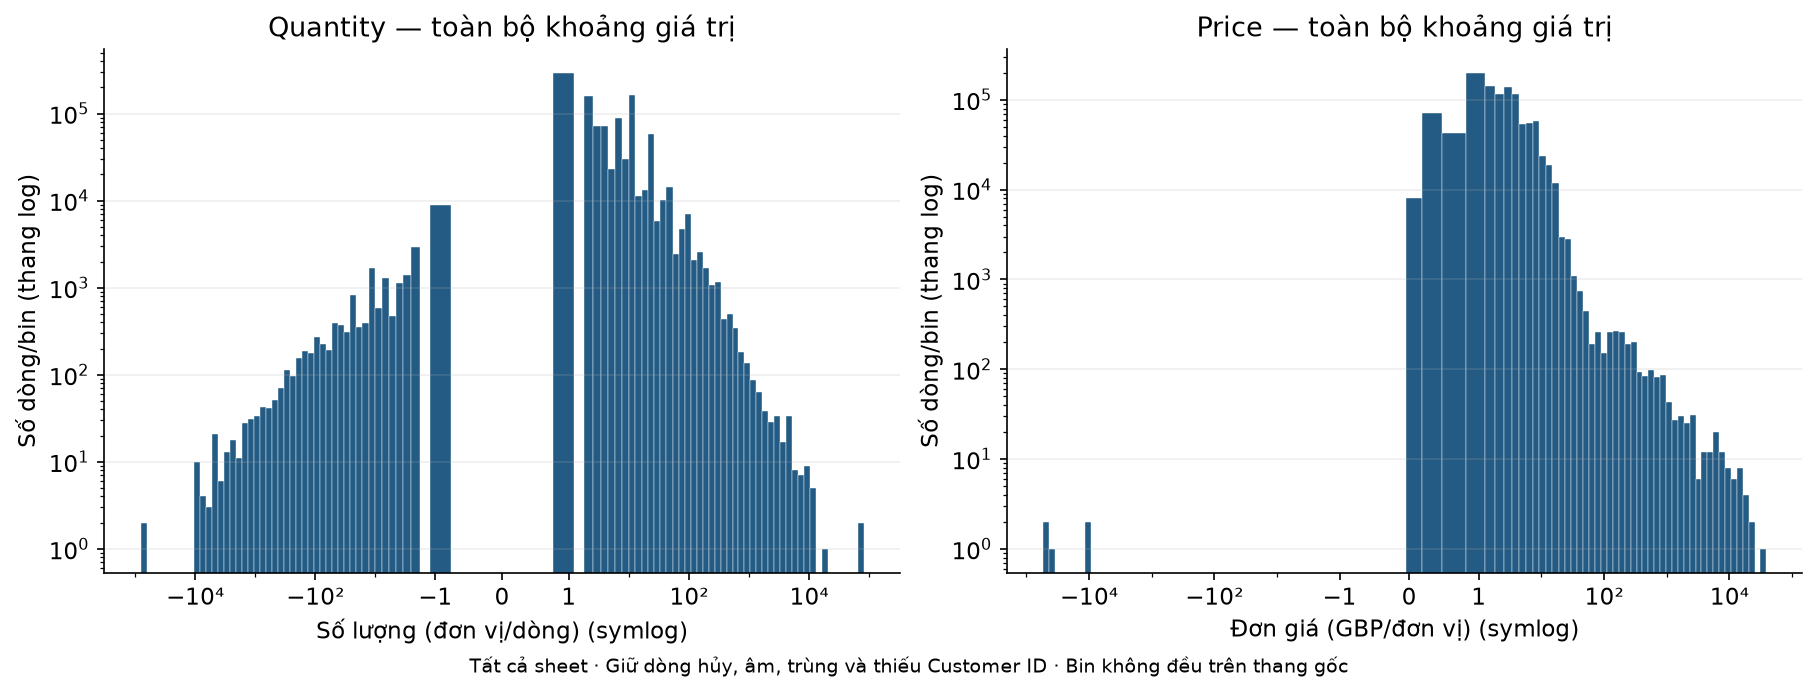

**Nhận xét.** Cả hai phân phối được hiển thị trên toàn bộ miền giá trị, kể cả dấu âm và 0. Đuôi dài giải thích vì sao trục tuyến tính toàn miền khó thể hiện phần tập trung; không lấy chiều cao các bin không đều làm mật độ và không coi thang log là thao tác làm sạch dữ liệu.

In [14]:
distribution_columns = [('Quantity', 'Số lượng (đơn vị/dòng)'), ('Price', 'Đơn giá (GBP/đơn vị)')]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), layout='constrained')
for ax, (column, label) in zip(axes, distribution_columns):
    values = eda[column].dropna()
    values = values[np.isfinite(values)]
    lo, hi = values.min(), values.max()
    transform = lambda value: np.sign(value) * np.log1p(np.abs(value))
    transformed_edges = np.linspace(transform(lo), transform(hi), 100)
    edges = np.sign(transformed_edges) * np.expm1(np.abs(transformed_edges))
    edges[0], edges[-1] = lo, hi  # bao gồm chính xác hai cực trị, tránh sai số nghịch biến đổi
    ax.hist(values, bins=edges, color=BLUE, edgecolor='white', linewidth=0.2)
    ax.set_xscale('symlog', linthresh=1)
    ax.set_xticks([-10000, -100, -1, 0, 1, 100, 10000])
    ax.set_xticklabels(['−10⁴', '−10²', '−1', '0', '1', '10²', '10⁴'])
    ax.set_yscale('log')
    ax.set(title=f'{column} — toàn bộ khoảng giá trị', xlabel=label + ' (symlog)', ylabel='Số dòng/bin (thang log)')
    ax.grid(axis='y', alpha=0.2)
fig.supxlabel('Tất cả sheet · Giữ dòng hủy, âm, trùng và thiếu Customer ID · Bin không đều trên thang gốc', fontsize=9)
show_figure(fig, 'quantity_price_full_range.png')
note('Cả hai phân phối được hiển thị trên toàn bộ miền giá trị, kể cả dấu âm và 0. '
     'Đuôi dài giải thích vì sao trục tuyến tính toàn miền khó thể hiện phần tập trung; '
     'không lấy chiều cao các bin không đều làm mật độ và không coi thang log là thao tác làm sạch dữ liệu.')

#### 4.1.2. P01–P99 — giữ histogram phóng to hiện có

**Câu hỏi:** phần tập trung của Quantity và Price có hình dạng gì?

**Phạm vi/cách tính:** phân vị tính từ toàn bộ dữ liệu; chỉ những dòng trong vùng được đưa
vào hình này. Bảng ghi rõ trong/ngoài vùng. Đây là **giới hạn trực quan**, không xóa ngoại lai.

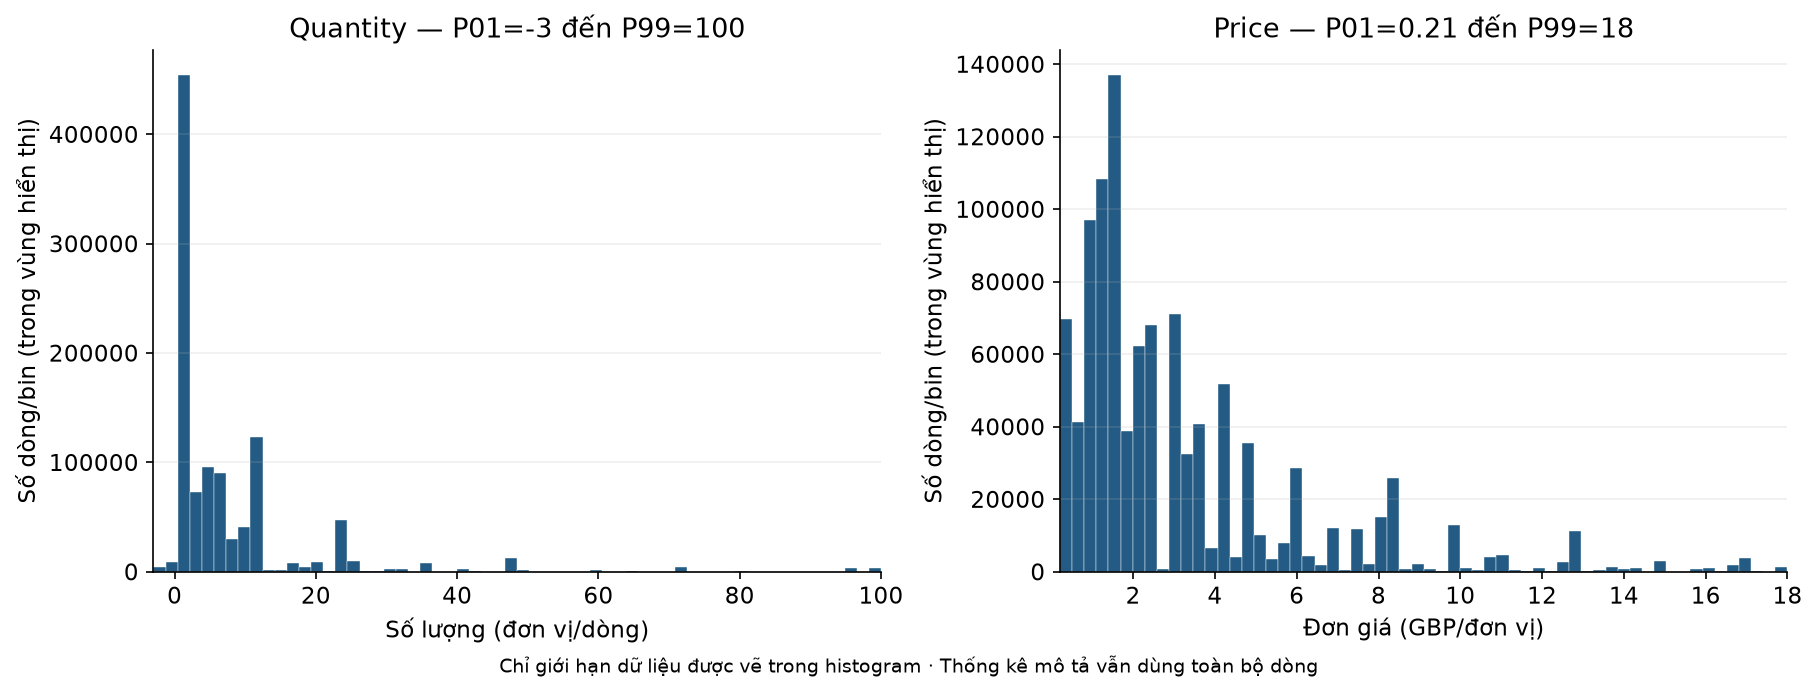

Biến,P01,P99,Dòng trong vùng,Dòng ngoài vùng,Ngoài vùng (%)
Quantity,-3.000,100.000,1047142,20229,1.895
Price,0.210,18.000,1046158,21213,1.987


**Nhận xét.** Quantity: 20.229 dòng ngoài vùng hiển thị (1.90%); Price: 21.213 dòng ngoài vùng hiển thị (1.99%). Các dòng này vẫn tồn tại trong raw, eda và mọi thống kê tổng thể. Tỷ lệ có thể khác 2% do phân phối rời rạc và các giá trị bằng ngưỡng.

In [15]:
zoom_records = []
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), layout='constrained')
for ax, (column, label) in zip(axes, distribution_columns):
    values = eda[column].dropna()
    lower, upper = values.quantile([0.01, 0.99])
    inside = values.between(lower, upper)
    ax.hist(values[inside], bins=60, color=BLUE, edgecolor='white', linewidth=0.2)
    ax.set(title=f'{column} — P01={lower:g} đến P99={upper:g}', xlabel=label,
           ylabel='Số dòng/bin (trong vùng hiển thị)', xlim=(lower, upper))
    ax.grid(axis='y', alpha=0.2)
    zoom_records.append({'Biến': column, 'P01': lower, 'P99': upper,
                         'Dòng trong vùng': int(inside.sum()), 'Dòng ngoài vùng': int((~inside).sum()),
                         'Ngoài vùng (%)': (~inside).mean() * 100})
fig.supxlabel('Chỉ giới hạn dữ liệu được vẽ trong histogram · Thống kê mô tả vẫn dùng toàn bộ dòng', fontsize=9)
show_figure(fig, 'quantity_price_histogram_p01_p99.png')
zoom_summary = pd.DataFrame(zoom_records)
show_table(zoom_summary, {'Ngoài vùng (%)': '{:.3f}', 'P01': '{:,.3f}', 'P99': '{:,.3f}'})
note('; '.join(f"{row['Biến']}: {vn_int(row['Dòng ngoài vùng'])} dòng ngoài vùng hiển thị ({row['Ngoài vùng (%)']:.2f}%)"
               for row in zoom_records) + '. Các dòng này vẫn tồn tại trong raw, eda và mọi thống kê tổng thể. '
     'Tỷ lệ có thể khác 2% do phân phối rời rạc và các giá trị bằng ngưỡng.')

#### 4.1.3. Boxplot toàn bộ dữ liệu — giữ hình hiện có

**Câu hỏi:** trung vị, IQR và điểm ngoài râu khác nhau thế nào giữa hai biến?

**Phạm vi/cách tính:** toàn bộ quan sát, râu 1,5 × IQR, vẫn vẽ điểm ngoài râu;
trục x symlog. Không diễn giải các điểm ngoài râu thành danh sách phải xóa.

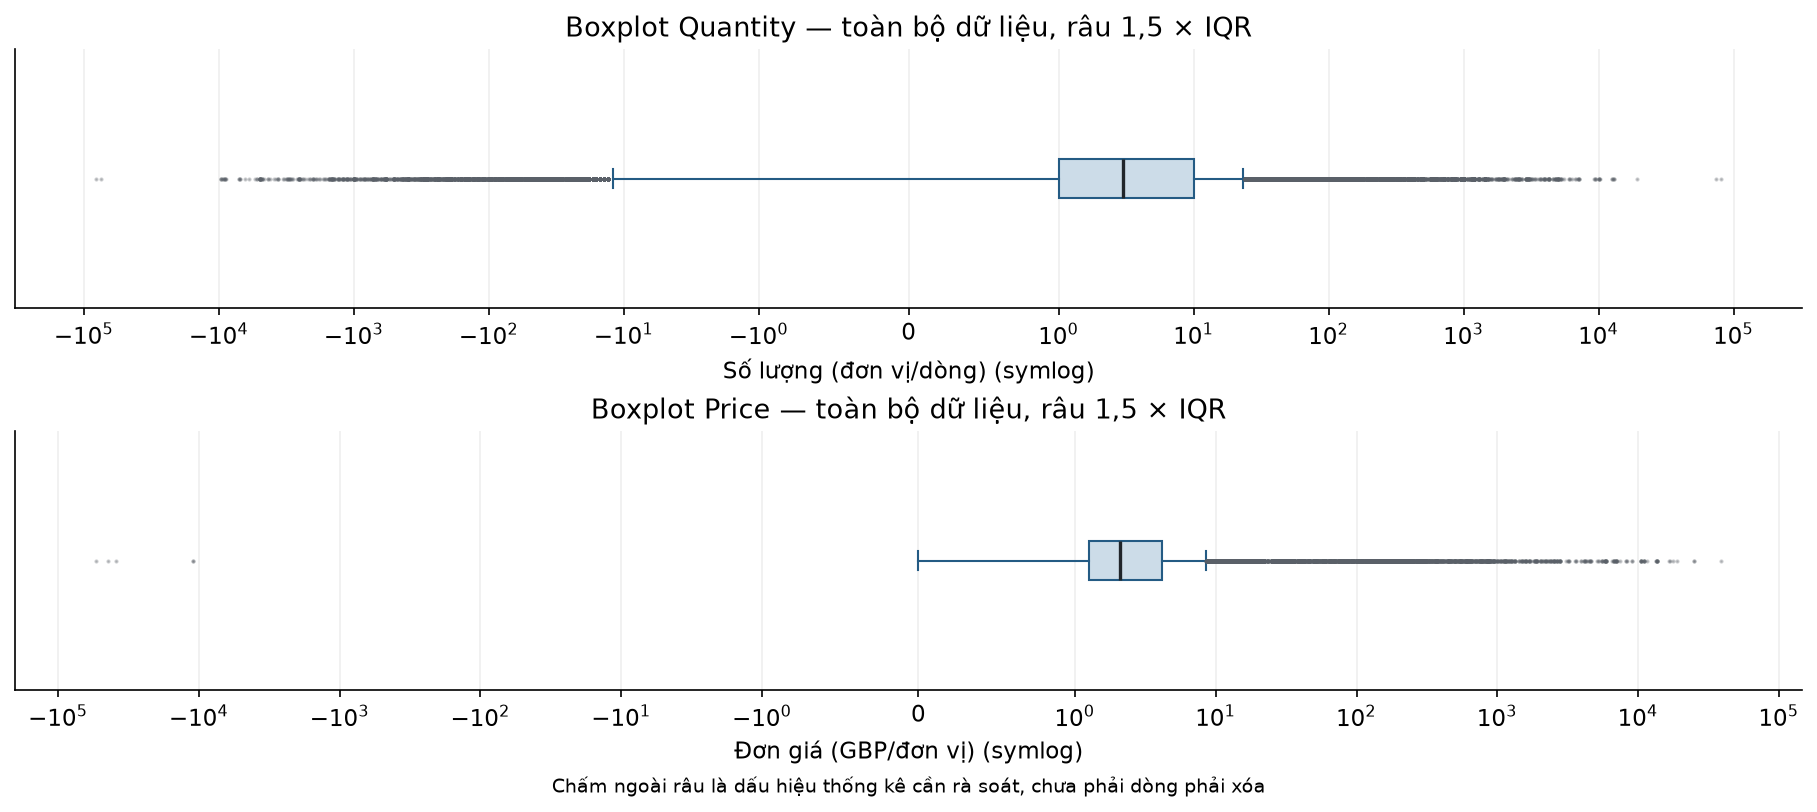

**Nhận xét.** Boxplot dùng toàn bộ quan sát và vẫn hiển thị điểm ngoài râu. Trung vị và hộp bị nén bởi đuôi dài ngay cả khi dùng symlog; histogram P01–P99 giúp đọc phần tập trung. Chính sách ngoại lai cần cân nhắc khách hàng mua sỉ và các bút toán đặc biệt, không áp dụng máy móc râu boxplot.

In [16]:
fig, axes = plt.subplots(2, 1, figsize=(12, 5.3), layout='constrained')
for ax, (column, label) in zip(axes, distribution_columns):
    ax.boxplot(eda[column].dropna().to_numpy(), orientation='horizontal', patch_artist=True,
               boxprops={'facecolor': '#CCDCE8', 'edgecolor': BLUE},
               medianprops={'color': '#20252A', 'linewidth': 1.6},
               whiskerprops={'color': BLUE}, capprops={'color': BLUE},
               flierprops={'marker': '.', 'markersize': 2, 'markerfacecolor': GRAY, 'markeredgecolor': GRAY, 'alpha': 0.3})
    ax.set_xscale('symlog', linthresh=1)
    ax.set(title=f'Boxplot {column} — toàn bộ dữ liệu, râu 1,5 × IQR', xlabel=label + ' (symlog)', yticks=[])
    ax.grid(axis='x', alpha=0.2)
fig.supxlabel('Chấm ngoài râu là dấu hiệu thống kê cần rà soát, chưa phải dòng phải xóa', fontsize=9)
show_figure(fig, 'quantity_price_boxplots.png')
note('Boxplot dùng toàn bộ quan sát và vẫn hiển thị điểm ngoài râu. '
     'Trung vị và hộp bị nén bởi đuôi dài ngay cả khi dùng symlog; histogram P01–P99 giúp đọc phần tập trung. '
     'Chính sách ngoại lai cần cân nhắc khách hàng mua sỉ và các bút toán đặc biệt, không áp dụng máy móc râu boxplot.')

#### 4.1.4. Phân phối giá trị dòng

**Câu hỏi:** giá trị đại số dòng có cả phần âm và đuôi lớn như thế nào?

**Phạm vi/cách tính:** toàn bộ LineValue hữu hạn; bin theo signed log1p,
trục x symlog, số dòng/bin thang log, giữ cả bút toán và dòng trùng.

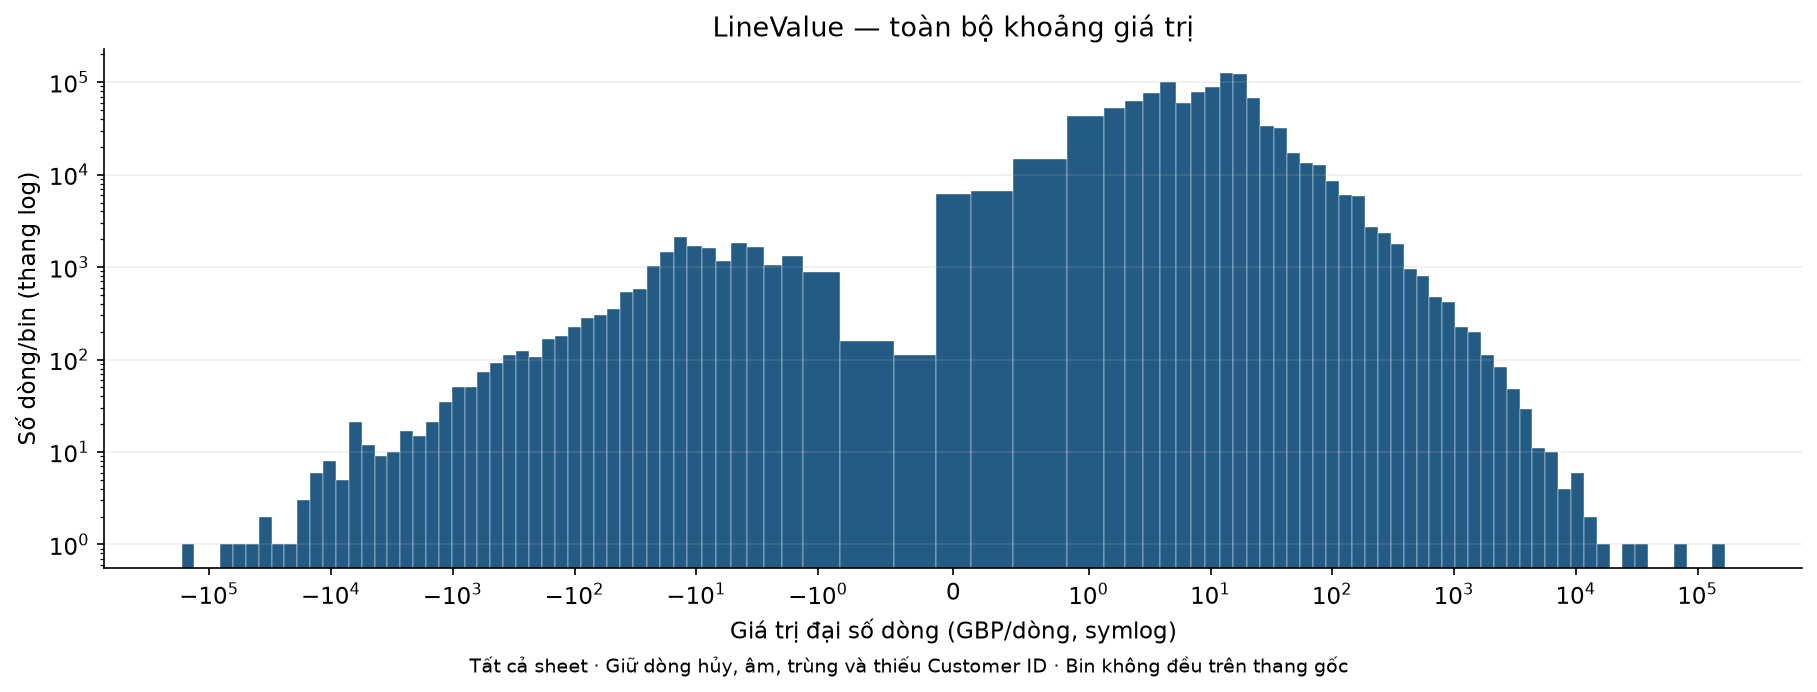

**Nhận xét.** LineValue có 19.498 dòng âm, 6.202 dòng bằng 0 và 1.041.671 dòng dương. Tổng đại số 19,287,250.57 GBP chưa phải doanh thu đã đối trừ/loại bản sao theo chính sách chính thức.

In [17]:
line_values = eda.loc[np.isfinite(eda['LineValue']), 'LineValue']
signed_log1p = lambda values: np.sign(values) * np.log1p(np.abs(values))
line_edges_transformed = np.linspace(signed_log1p(line_values.min()), signed_log1p(line_values.max()), 100)
line_edges = np.sign(line_edges_transformed) * np.expm1(np.abs(line_edges_transformed))
line_edges[0], line_edges[-1] = line_values.min(), line_values.max()
fig, ax = plt.subplots(figsize=(12, 4.5), layout='constrained')
ax.hist(line_values, bins=line_edges, color=BLUE, edgecolor='white', linewidth=0.2)
ax.set_xscale('symlog', linthresh=1)
ax.set_yscale('log')
ax.set(title='LineValue — toàn bộ khoảng giá trị', xlabel='Giá trị đại số dòng (GBP/dòng, symlog)',
       ylabel='Số dòng/bin (thang log)')
ax.grid(axis='y', alpha=0.2)
fig.supxlabel('Tất cả sheet · Giữ dòng hủy, âm, trùng và thiếu Customer ID · Bin không đều trên thang gốc', fontsize=9)
show_figure(fig, 'line_value_full_range.png')
note(f'LineValue có {vn_int(line_values.lt(0).sum())} dòng âm, {vn_int(line_values.eq(0).sum())} dòng bằng 0 '
     f'và {vn_int(line_values.gt(0).sum())} dòng dương. Tổng đại số {line_values.sum():,.2f} GBP '
     'chưa phải doanh thu đã đối trừ/loại bản sao theo chính sách chính thức.')

### 4.2. Categorical — Country

**Câu hỏi:** chứng từ tập trung ở những nhãn quốc gia nào?

**Phạm vi/cách tính:** số InvoiceKey duy nhất **bên trong từng CountryKey** sau trim;
giữ hủy, lượng/giá âm, trùng và thiếu khách hàng. Tỷ trọng dùng tổng cặp
quốc gia–hóa đơn; chỉ cộng như nhóm loại trừ nhau khi kiểm tra mâu thuẫn đạt.
Bảng giữ toàn bộ nhãn, hình giữ top 10 như phiên bản trước.

In [18]:
country_eligible = eda['CountryKey'].notna() & eda['InvoiceKey'].notna()
country_pairs = eda.loc[country_eligible, ['CountryKey', 'InvoiceKey']].drop_duplicates()
country_counts = country_pairs.groupby('CountryKey')['InvoiceKey'].nunique().sort_values(ascending=False)
n_country_pairs = int(country_counts.sum())
country_table = country_counts.rename('Số hóa đơn duy nhất trong quốc gia').to_frame()
country_table['Tỷ trọng cặp quốc gia–hóa đơn (%)'] = country_counts / n_country_pairs * 100
show_table(country_table.reset_index(names='Quốc gia'), {'Tỷ trọng cặp quốc gia–hóa đơn (%)': '{:.3f}'})
note(f'Có {vn_int((~country_eligible).sum())} dòng thiếu quốc gia/mã hóa đơn không được nhóm; '
     f'{vn_int(n_country_pairs)} cặp quốc gia–hóa đơn so với {vn_int(n_invoices)} mã hóa đơn toàn cục. '
     f'{vn_int(len(multi_country))} mã gắn nhiều quốc gia; tỷ trọng dùng mẫu số {vn_int(n_country_pairs)} cặp để tránh giả định nhóm loại trừ nhau.')

Quốc gia,Số hóa đơn duy nhất trong quốc gia,Tỷ trọng cặp quốc gia–hóa đơn (%)
United Kingdom,49108,91.572
Germany,1095,2.042
EIRE,806,1.503
France,746,1.391
Netherlands,250,0.466
Spain,188,0.351
Belgium,183,0.341
Sweden,129,0.241
Portugal,124,0.231
Switzerland,123,0.229


**Nhận xét.** Có 0 dòng thiếu quốc gia/mã hóa đơn không được nhóm; 53.628 cặp quốc gia–hóa đơn so với 53.628 mã hóa đơn toàn cục. 0 mã gắn nhiều quốc gia; tỷ trọng dùng mẫu số 53.628 cặp để tránh giả định nhóm loại trừ nhau.

**Nhận xét.** Không phát hiện mã hóa đơn gắn nhiều quốc gia theo phép kiểm tra trên toàn bộ workbook.

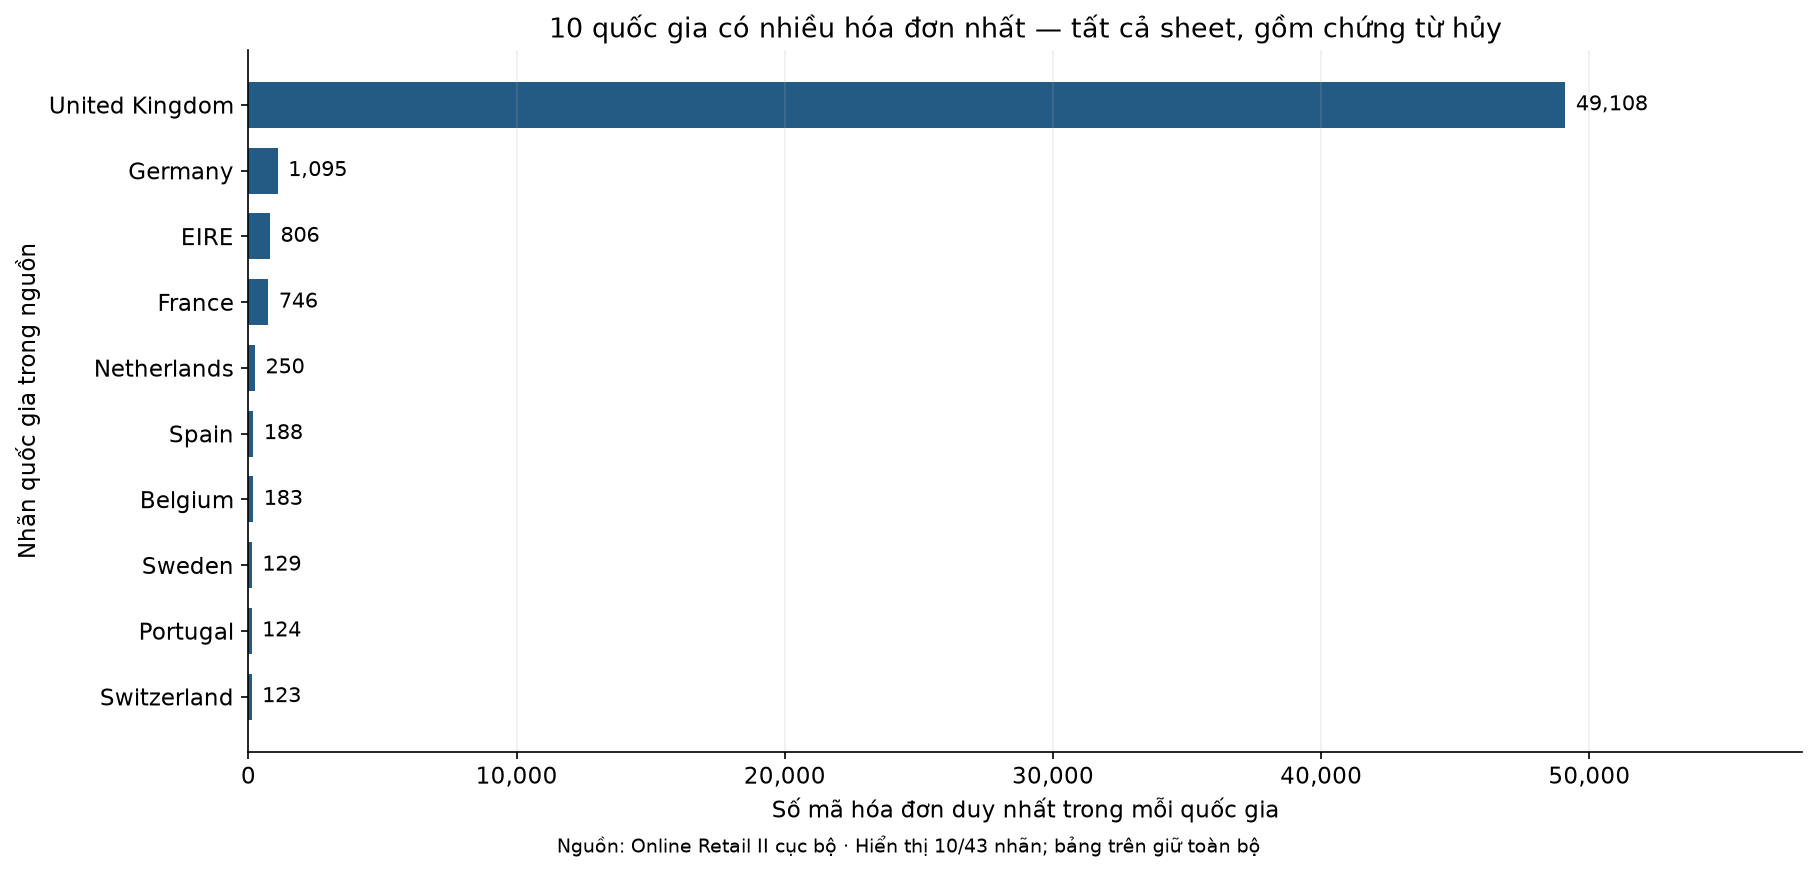

**Nhận xét.** United Kingdom đứng đầu với 49.108 mã hóa đơn, chiếm 91.57% các cặp quốc gia–hóa đơn; 10 nhãn đầu chiếm 98.37%. Giao dịch tập trung mạnh vào nhãn đứng đầu. Chưa suy rộng thành cơ cấu thị trường hiện tại hoặc giá trị/khả năng sinh lời của khách hàng.

In [19]:
if len(multi_country):
    country_conflicts = eda.loc[eda['InvoiceKey'].isin(multi_country.index)].groupby('InvoiceKey').agg(
        Countries=('CountryKey', lambda values: ', '.join(sorted(values.dropna().unique()))),
        Customers=('Customer ID', 'nunique'), Rows=('InvoiceKey', 'size'),
        FirstDate=('InvoiceDateParsed', 'min'), LastDate=('InvoiceDateParsed', 'max'),
    ).reset_index()
    show_table(country_conflicts.head(10))
    note('Hiển thị tối đa 10 mã hóa đơn có quốc gia mâu thuẫn để bàn giao kiểm tra. '
         'Không tự chọn một quốc gia hay ghép khóa với Customer ID để che mâu thuẫn.')
else:
    note('Không phát hiện mã hóa đơn gắn nhiều quốc gia theo phép kiểm tra trên toàn bộ workbook.')

top_countries = country_counts.head(10).sort_values()
fig, ax = plt.subplots(figsize=(12, 5.7), layout='constrained')
bars = ax.barh(top_countries.index, top_countries.values, color=BLUE, height=0.7)
ax.bar_label(bars, labels=[f'{value:,}' for value in top_countries], padding=5, fontsize=10)
ax.set(xlabel='Số mã hóa đơn duy nhất trong mỗi quốc gia', ylabel='Nhãn quốc gia trong nguồn',
       title='10 quốc gia có nhiều hóa đơn nhất — tất cả sheet, gồm chứng từ hủy',
       xlim=(0, top_countries.max() * 1.18))
ax.xaxis.set_major_formatter(StrMethodFormatter('{x:,.0f}'))
ax.grid(axis='x', alpha=0.2)
fig.supxlabel(f'Nguồn: Online Retail II cục bộ · Hiển thị 10/{len(country_counts)} nhãn; bảng trên giữ toàn bộ', fontsize=9)
show_figure(fig, 'invoices_by_country.png')
top_country = country_counts.index[0]
top_country_share = float(country_counts.iloc[0] / n_country_pairs)
top10_share = float(country_counts.head(10).sum() / n_country_pairs)
note(f'{top_country} đứng đầu với {vn_int(country_counts.iloc[0])} mã hóa đơn, '
     f'chiếm {top_country_share:.2%} các cặp quốc gia–hóa đơn; 10 nhãn đầu chiếm {top10_share:.2%}. '
     'Giao dịch tập trung mạnh vào nhãn đứng đầu. Chưa suy rộng thành cơ cấu thị trường hiện tại hoặc giá trị/khả năng sinh lời của khách hàng.')

### 4.3. Categorical — dấu hiệu hóa đơn tiền tố C

**Câu hỏi:** số dòng và số mã chứng từ có tiền tố C chiếm tỷ lệ bao nhiêu?

**Phạm vi/cách tính:** phân loại theo InvoiceKey, đếm dòng và mã riêng.
Tỷ lệ mã C = số mã C / số mã chứng từ có định danh. Đây là **tỷ lệ chứng từ C**,
không phải tỷ lệ đơn mua bị hủy hay tỷ lệ hoàn trả đã ghép với hóa đơn gốc.

PrefixStatus,Rows,Invoices,Tỷ lệ dòng (%),Tỷ lệ mã (%)
Không có tiền tố C,1047877,45336,98.17,84.54
Có tiền tố C,19494,8292,1.83,15.46
Thiếu mã hóa đơn,0,0,0.00,0.00


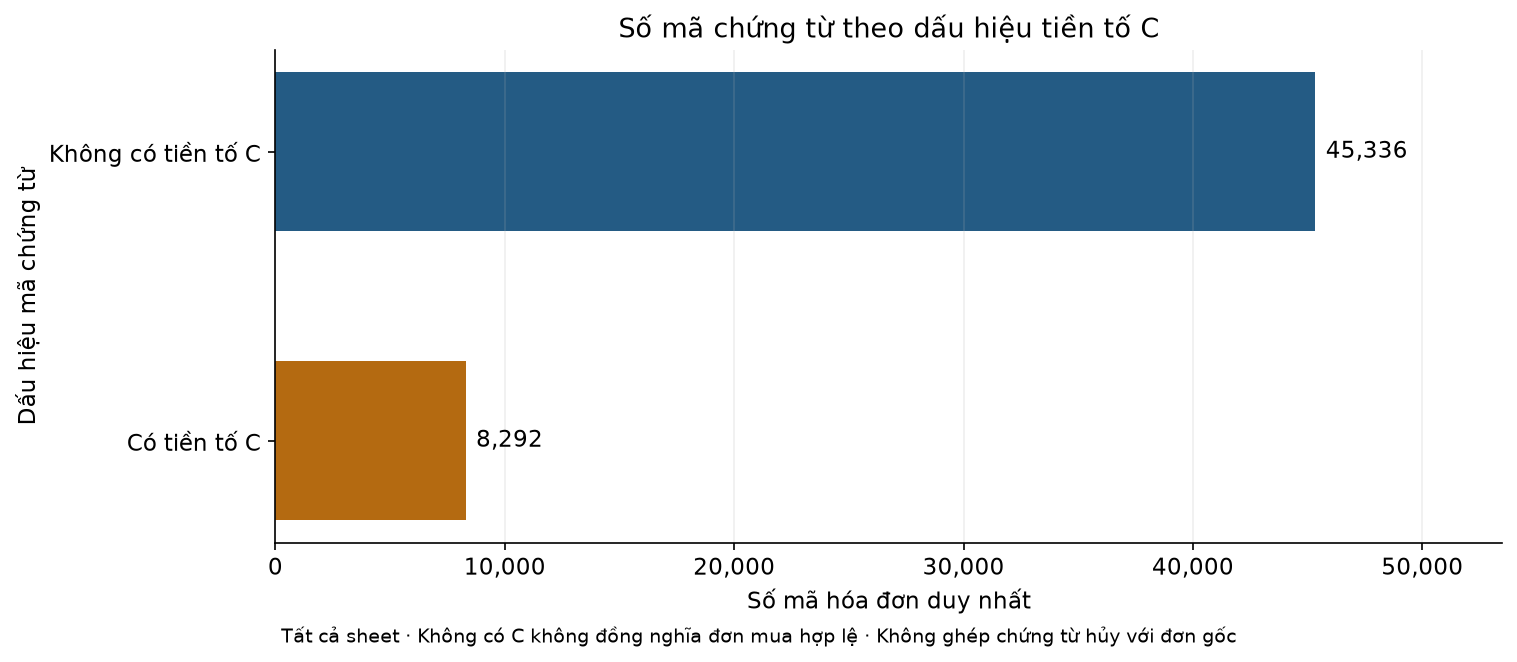

**Nhận xét.** Có 8.292 mã C trên 53.628 mã chứng từ (15.46%); tỷ lệ dòng C là 1.83%. Hai tỷ lệ có đơn vị khác nhau; không suy ra số đơn mua thực sự bị hủy từ hai số này.

In [20]:
PREFIX_ORDER = ['Không có tiền tố C', 'Có tiền tố C']
eda['PrefixStatus'] = pd.Series(np.where(cancelled, PREFIX_ORDER[1], PREFIX_ORDER[0]), index=eda.index)
eda.loc[eda['InvoiceKey'].isna(), 'PrefixStatus'] = 'Thiếu mã hóa đơn'
prefix_summary = (eda.groupby('PrefixStatus').agg(Rows=('PrefixStatus', 'size'),
                  Invoices=('InvoiceKey', 'nunique')).reindex(PREFIX_ORDER + ['Thiếu mã hóa đơn'], fill_value=0))
prefix_summary['Tỷ lệ dòng (%)'] = prefix_summary['Rows'] / n_rows * 100
prefix_summary['Tỷ lệ mã (%)'] = prefix_summary['Invoices'] / n_invoices * 100
show_table(prefix_summary.reset_index(), {'Tỷ lệ dòng (%)': '{:.2f}', 'Tỷ lệ mã (%)': '{:.2f}'})
fig, ax = plt.subplots(figsize=(10, 4.3), layout='constrained')
prefix_bars = ax.barh(PREFIX_ORDER[::-1], prefix_summary.loc[PREFIX_ORDER[::-1], 'Invoices'],
                     color=[GOLD, BLUE], height=0.55)
ax.bar_label(prefix_bars, labels=[f'{v:,}' for v in prefix_summary.loc[PREFIX_ORDER[::-1], 'Invoices']], padding=5)
ax.set(title='Số mã chứng từ theo dấu hiệu tiền tố C', xlabel='Số mã hóa đơn duy nhất',
       ylabel='Dấu hiệu mã chứng từ', xlim=(0, prefix_summary['Invoices'].max() * 1.18))
ax.xaxis.set_major_formatter(StrMethodFormatter('{x:,.0f}'))
ax.grid(axis='x', alpha=0.2)
fig.supxlabel('Tất cả sheet · Không có C không đồng nghĩa đơn mua hợp lệ · Không ghép chứng từ hủy với đơn gốc', fontsize=9)
show_figure(fig, 'invoices_by_c_prefix.png')
note(f'Có {vn_int(n_cancel_invoices)} mã C trên {vn_int(n_invoices)} mã chứng từ '
     f'({n_cancel_invoices / n_invoices:.2%}); tỷ lệ dòng C là {n_cancel_rows / n_rows:.2%}. '
     'Hai tỷ lệ có đơn vị khác nhau; không suy ra số đơn mua thực sự bị hủy từ hai số này.')

## 5. Phân tích hai biến

### 5.1. Numerical – Numerical: Quantity và Price

**Câu hỏi:** các dòng có Quantity lớn có Price thấp hơn không?

**Phạm vi/cách tính:** mọi dòng có cả hai giá trị hữu hạn, giữ cả âm, 0, C và trùng;
không dùng LineValue để tránh mối liên hệ tích số hiển nhiên. Hexbin tổng hợp toàn bộ dòng,
không lấy mẫu. Hai tọa độ được biến đổi **signed log1p** chỉ để vẽ; màu là số dòng/ô thang log.
Pearson và Spearman tính trên giá trị gốc, không coi dòng mặt hàng phụ thuộc cùng hóa đơn là mẫu độc lập để kiểm định.

Cặp biến,Số dòng,Pearson (giá trị gốc),Spearman (giá trị gốc)
Quantity – Price,1067371,-0.0013,-0.3990


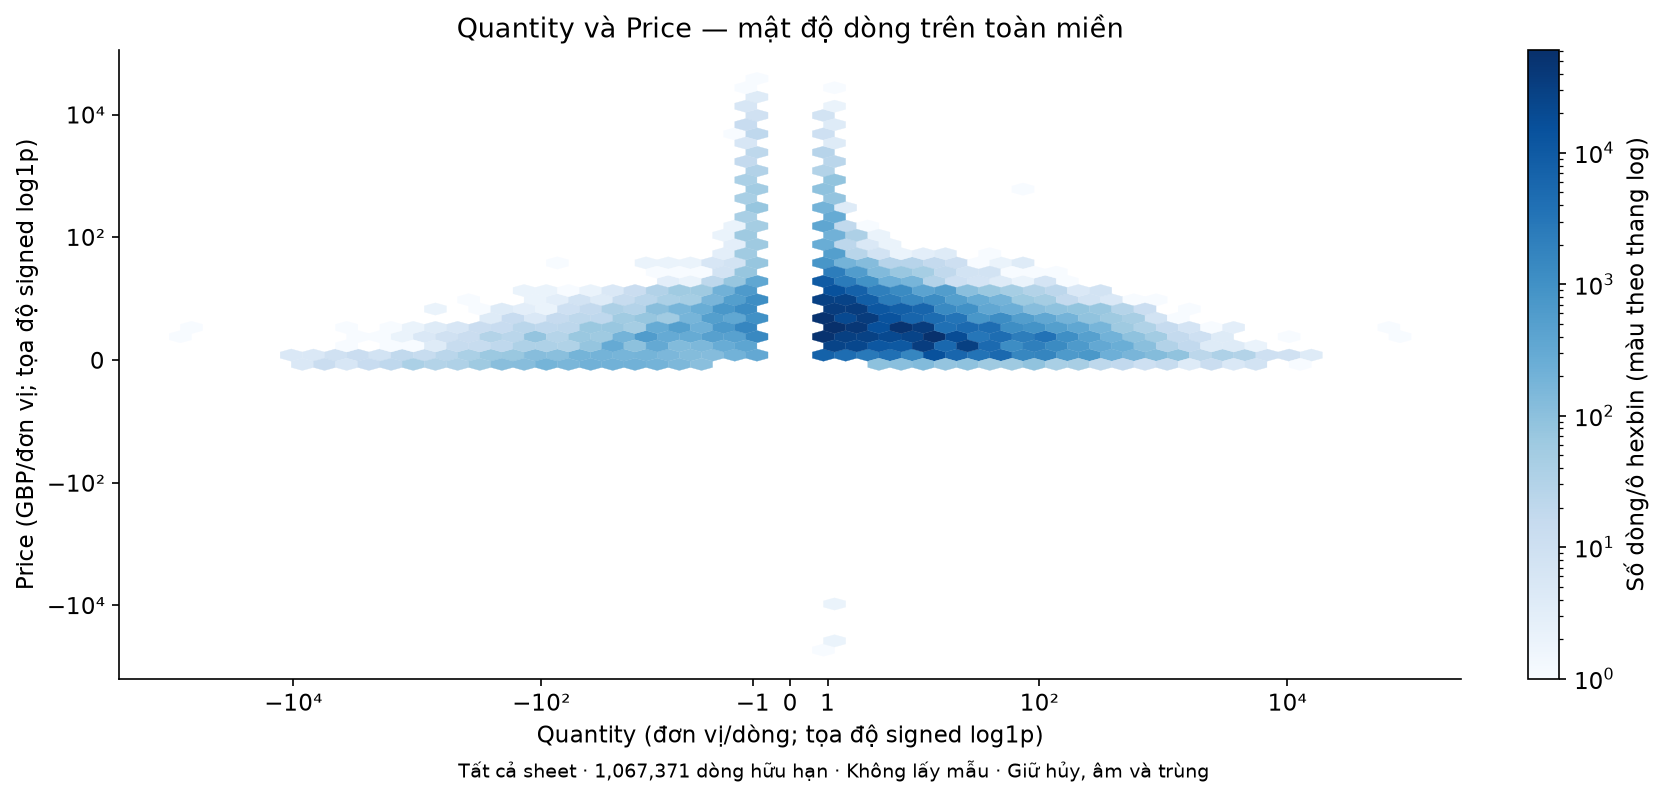

**Nhận xét.** Trên 1.067.371 dòng, Pearson = -0.0013, Spearman = -0.3990. Các hệ số mô tả hai dạng liên hệ khác nhau và chịu ảnh hưởng của bút toán/cơ cấu mặt hàng. Chưa đủ để khẳng định mua nhiều được giảm giá; cần đối chiếu cùng StockCode, thời điểm và nghiệp vụ.

In [21]:
pair_mask = np.isfinite(eda['Quantity']) & np.isfinite(eda['Price'])
numeric_pair = eda.loc[pair_mask, ['Quantity', 'Price']]
pair_correlations = pd.DataFrame([
    {'Cặp biến': 'Quantity – Price', 'Số dòng': len(numeric_pair),
     'Pearson (giá trị gốc)': numeric_pair['Quantity'].corr(numeric_pair['Price'], method='pearson'),
     'Spearman (giá trị gốc)': numeric_pair['Quantity'].corr(numeric_pair['Price'], method='spearman')}
])
show_table(pair_correlations, {'Pearson (giá trị gốc)': '{:.4f}', 'Spearman (giá trị gốc)': '{:.4f}'})
fig, ax = plt.subplots(figsize=(11, 5.2), layout='constrained')
pair_hexbin = ax.hexbin(signed_log1p(numeric_pair['Quantity']), signed_log1p(numeric_pair['Price']),
                       gridsize=55, mincnt=1, bins='log', cmap='Blues', linewidths=0.15)
pair_hexbin_count = int(pair_hexbin.get_array().sum())
colorbar = fig.colorbar(pair_hexbin, ax=ax)
colorbar.set_label('Số dòng/ô hexbin (màu theo thang log)')
tick_values = np.array([-10000, -100, -1, 0, 1, 100, 10000])
tick_labels = ['−10⁴', '−10²', '−1', '0', '1', '10²', '10⁴']
ax.set_xticks(signed_log1p(tick_values), tick_labels)
ax.set_yticks(signed_log1p(np.array([-10000, -100, 0, 100, 10000])), ['−10⁴', '−10²', '0', '10²', '10⁴'])
ax.set(title='Quantity và Price — mật độ dòng trên toàn miền',
       xlabel='Quantity (đơn vị/dòng; tọa độ signed log1p)',
       ylabel='Price (GBP/đơn vị; tọa độ signed log1p)')
fig.supxlabel(f'Tất cả sheet · {len(numeric_pair):,} dòng hữu hạn · Không lấy mẫu · Giữ hủy, âm và trùng', fontsize=9)
show_figure(fig, 'quantity_vs_price_hexbin.png')
note(f'Trên {vn_int(len(numeric_pair))} dòng, Pearson = {pair_correlations.iloc[0, 2]:.4f}, '
     f'Spearman = {pair_correlations.iloc[0, 3]:.4f}. '
     'Các hệ số mô tả hai dạng liên hệ khác nhau và chịu ảnh hưởng của bút toán/cơ cấu mặt hàng. '
     'Chưa đủ để khẳng định mua nhiều được giảm giá; cần đối chiếu cùng StockCode, thời điểm và nghiệp vụ.')

### 5.2. Categorical – Categorical: Country và dấu hiệu C

**Câu hỏi:** tỷ trọng chứng từ có C có giống nhau giữa các quốc gia nhiều hóa đơn không?

**Phạm vi/cách tính:** top 5 nhãn theo số mã hóa đơn trên toàn cửa sổ, giữ ổn định danh sách;
đếm InvoiceKey duy nhất trong mỗi cặp Country × trạng thái C. Chuẩn hóa mỗi thanh về 100%
trên số chứng từ có mã tại chính quốc gia đó; ghi mẫu số ở nhãn. Không gọi đây là tỷ lệ hoàn trả của khách hàng.

CountryKey,Mã không có C,Mã C,Tổng mã trong quốc gia,Mã C (%)
United Kingdom,41793,7315,49108,14.90
Germany,789,306,1095,27.95
EIRE,626,180,806,22.33
France,622,124,746,16.62
Netherlands,229,21,250,8.40


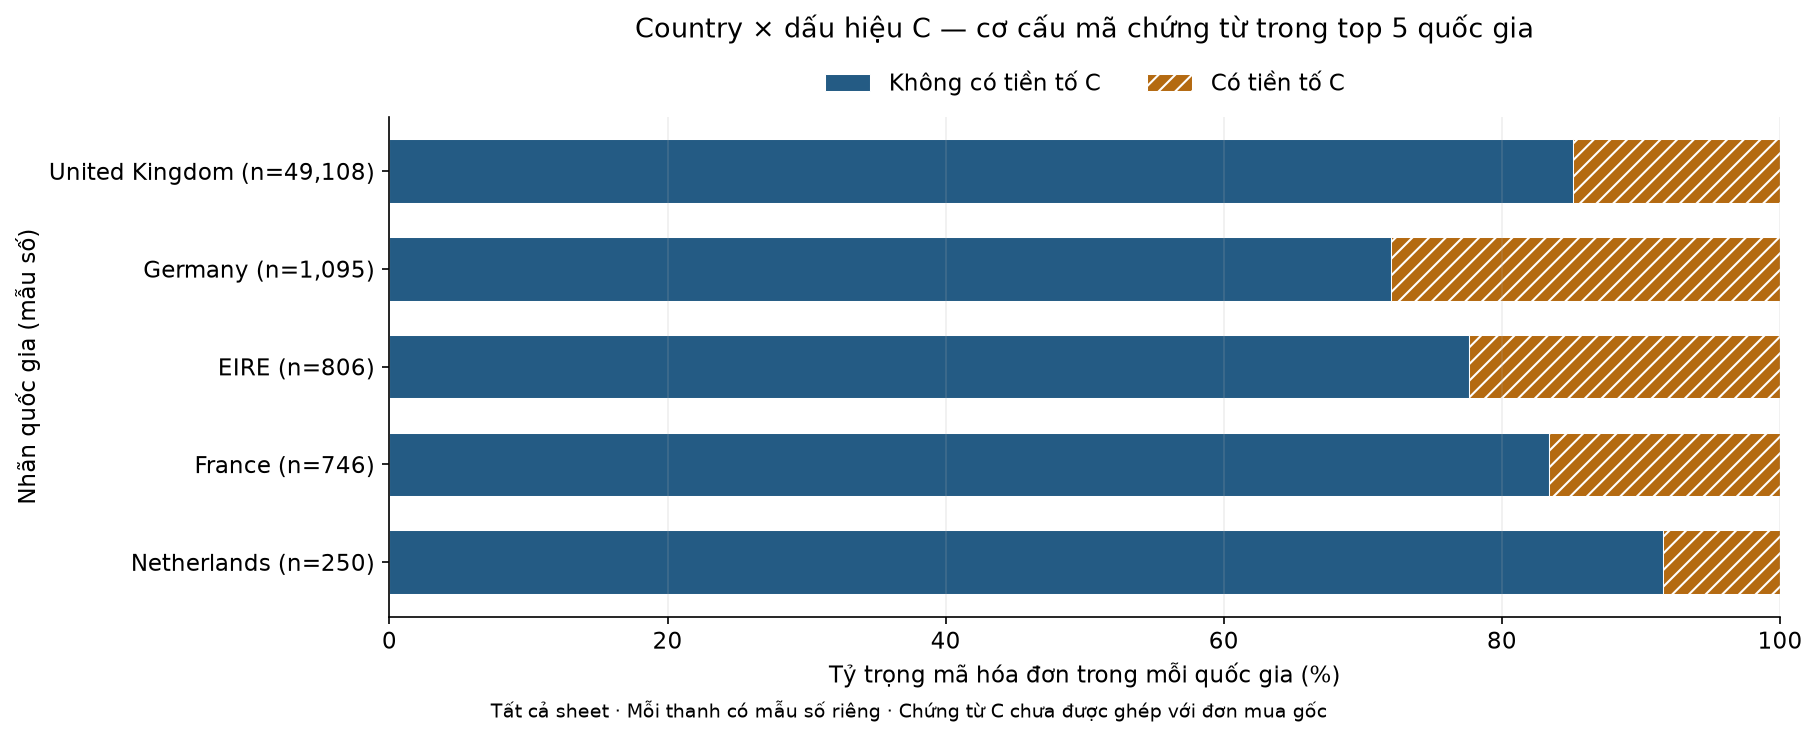

**Nhận xét.** Trong top 5, tỷ trọng mã C từ 8.40% (Netherlands) đến 27.95% (Germany). Mẫu số khác nhau và đây là chứng từ, không phải khách hàng; chưa suy ra nguyên nhân hoặc hiệu quả kinh doanh.

In [22]:
analysis_countries = country_counts.head(5).index.tolist()
country_prefix_counts = (eda.loc[country_eligible].groupby(['CountryKey', 'PrefixStatus'])['InvoiceKey']
                         .nunique().unstack('PrefixStatus', fill_value=0)
                         .reindex(index=analysis_countries, columns=PREFIX_ORDER, fill_value=0))
country_prefix_share = country_prefix_counts.div(country_prefix_counts.sum(axis=1), axis=0) * 100
country_prefix_view = country_prefix_counts.rename(columns={PREFIX_ORDER[0]: 'Mã không có C', PREFIX_ORDER[1]: 'Mã C'})
country_prefix_view['Tổng mã trong quốc gia'] = country_prefix_counts.sum(axis=1)
country_prefix_view['Mã C (%)'] = country_prefix_share[PREFIX_ORDER[1]]
show_table(country_prefix_view.reset_index(), {'Mã C (%)': '{:.2f}'})
fig, ax = plt.subplots(figsize=(12, 4.8), layout='constrained')
y = np.arange(len(analysis_countries))
left = np.zeros(len(y))
for status, color, hatch in zip(PREFIX_ORDER, [BLUE, GOLD], ['', '///']):
    ax.barh(y, country_prefix_share[status], left=left, color=color, height=0.65,
            label=status, hatch=hatch, edgecolor='white', linewidth=0.5)
    left += country_prefix_share[status].to_numpy()
ax.set_yticks(y, [f'{country} (n={country_prefix_counts.loc[country].sum():,})' for country in analysis_countries])
ax.invert_yaxis()
ax.set(title='Country × dấu hiệu C — cơ cấu mã chứng từ trong top 5 quốc gia',
       xlabel='Tỷ trọng mã hóa đơn trong mỗi quốc gia (%)', ylabel='Nhãn quốc gia (mẫu số)', xlim=(0, 100))
ax.set_title('Country × dấu hiệu C — cơ cấu mã chứng từ trong top 5 quốc gia', pad=38)
ax.legend(loc='lower center', bbox_to_anchor=(0.5, 1.0), ncol=2, frameon=False)
ax.grid(axis='x', alpha=0.2)
fig.supxlabel('Tất cả sheet · Mỗi thanh có mẫu số riêng · Chứng từ C chưa được ghép với đơn mua gốc', fontsize=9)
show_figure(fig, 'c_prefix_share_by_country.png')
cancel_shares = country_prefix_share[PREFIX_ORDER[1]]
note(f'Trong top 5, tỷ trọng mã C từ {cancel_shares.min():.2f}% ({cancel_shares.idxmin()}) '
     f'đến {cancel_shares.max():.2f}% ({cancel_shares.idxmax()}). '
     'Mẫu số khác nhau và đây là chứng từ, không phải khách hàng; chưa suy ra nguyên nhân hoặc hiệu quả kinh doanh.')

### 5.3. Numerical – Categorical: LineValue và Country

**Câu hỏi:** trung vị và độ phân tán giá trị dòng khác nhau ra sao giữa các quốc gia?

**Phạm vi/cách tính:** toàn bộ dòng LineValue hữu hạn thuộc cùng top 5 ở mục 5.2;
giữ C, âm, trùng và thiếu khách hàng. Boxplot trên toàn miền với symlog, râu 1,5 × IQR,
vẫn hiển thị điểm ngoài râu. Đơn vị là **GBP/dòng**, không phải giá trị hóa đơn hay chi tiêu/khách hàng.

Country,Số dòng,Q1 (GBP/dòng),Trung vị (GBP/dòng),Q3 (GBP/dòng),Min (GBP/dòng),Max (GBP/dòng)
United Kingdom,981330,3.35,8.47,16.95,"-168,469.60","168,469.60"
Germany,17624,12.50,17.00,23.40,-715.02,876.00
EIRE,17866,13.50,17.40,29.90,"-2,736.16","2,736.16"
France,14330,10.40,16.50,23.40,"-8,322.12","4,161.06"
Netherlands,5140,16.50,69.60,145.00,-947.08,"4,992.00"


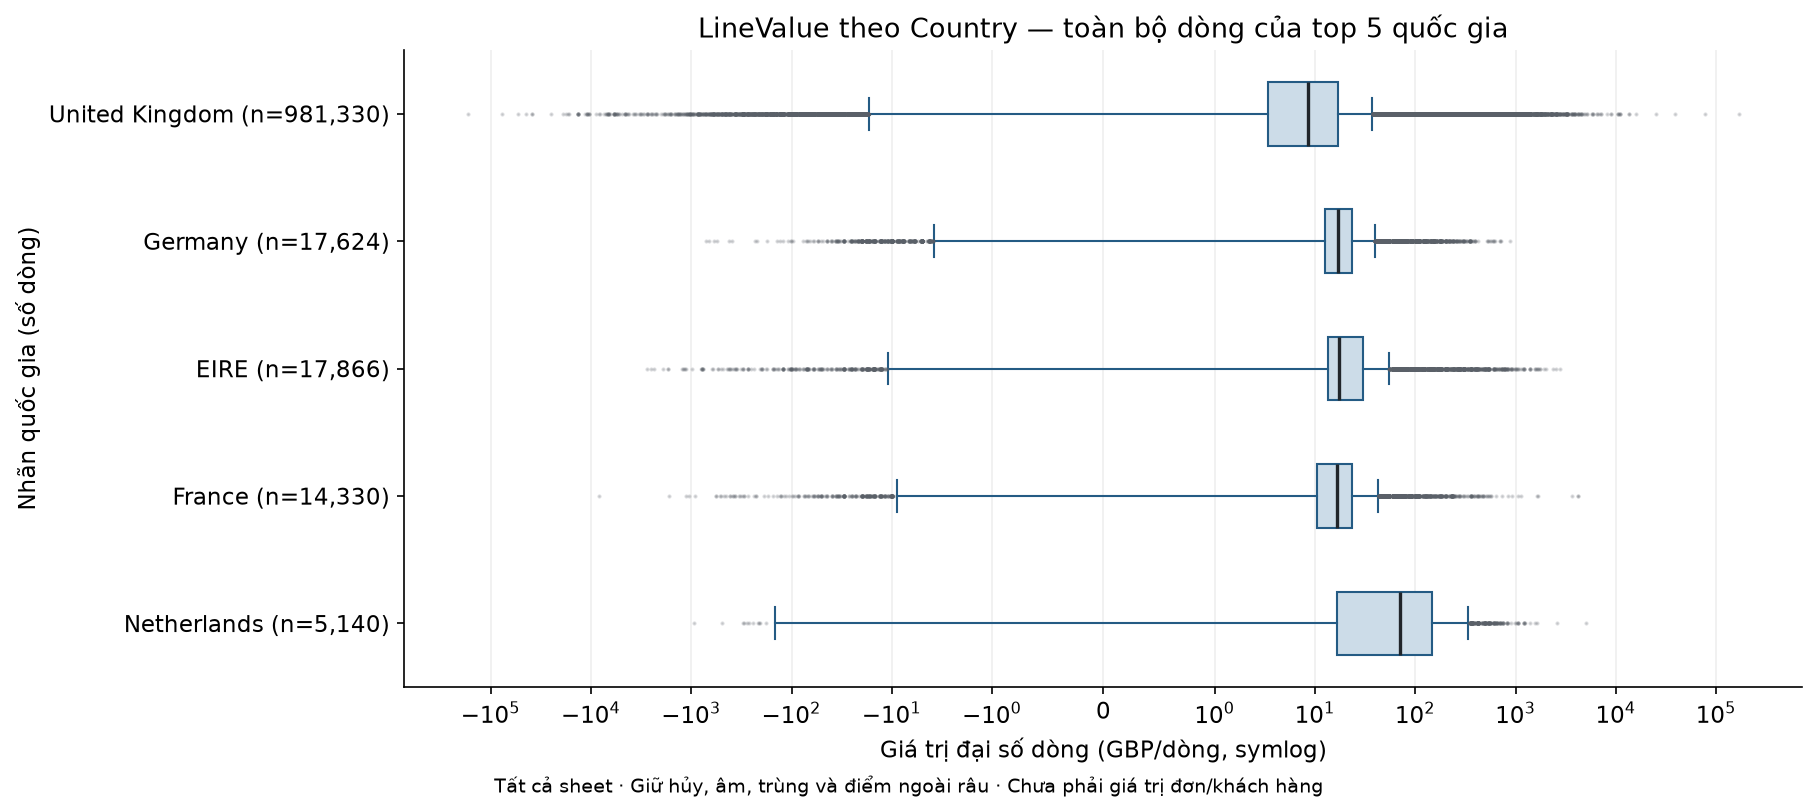

**Nhận xét.** Trung vị giá trị dòng trong top 5 từ 8.47 GBP (United Kingdom) đến 69.60 GBP (Netherlands). Bảng phân vị đọc phần trung tâm, hình cho thấy cả đuôi. Khác biệt có thể liên quan cơ cấu mặt hàng/đơn; chưa được dùng để xếp hạng giá trị khách hàng theo quốc gia.

In [23]:
country_line_values = {country: eda.loc[eda['CountryKey'].eq(country).fillna(False)
                                      & np.isfinite(eda['LineValue']), 'LineValue']
                       for country in analysis_countries}
country_value_summary = pd.DataFrame([{
    'Country': country, 'Số dòng': len(values), 'Q1 (GBP/dòng)': values.quantile(0.25),
    'Trung vị (GBP/dòng)': values.median(), 'Q3 (GBP/dòng)': values.quantile(0.75),
    'Min (GBP/dòng)': values.min(), 'Max (GBP/dòng)': values.max(),
} for country, values in country_line_values.items()])
show_table(country_value_summary, {c: '{:,.2f}' for c in country_value_summary.columns if 'GBP' in c})
fig, ax = plt.subplots(figsize=(12, 5.3), layout='constrained')
ax.boxplot([v.to_numpy() for v in country_line_values.values()], orientation='horizontal',
           tick_labels=[f'{c} (n={len(v):,})' for c, v in country_line_values.items()], patch_artist=True,
           boxprops={'facecolor': '#CCDCE8', 'edgecolor': BLUE}, medianprops={'color': '#20252A', 'linewidth': 1.6},
           whiskerprops={'color': BLUE}, capprops={'color': BLUE},
           flierprops={'marker': '.', 'markersize': 2, 'alpha': 0.2, 'markerfacecolor': GRAY, 'markeredgecolor': GRAY})
ax.set_xscale('symlog', linthresh=1)
ax.invert_yaxis()
ax.set(title='LineValue theo Country — toàn bộ dòng của top 5 quốc gia',
       xlabel='Giá trị đại số dòng (GBP/dòng, symlog)', ylabel='Nhãn quốc gia (số dòng)')
ax.grid(axis='x', alpha=0.2)
fig.supxlabel('Tất cả sheet · Giữ hủy, âm, trùng và điểm ngoài râu · Chưa phải giá trị đơn/khách hàng', fontsize=9)
show_figure(fig, 'line_value_by_country_boxplot.png')
country_medians = country_value_summary.set_index('Country')['Trung vị (GBP/dòng)']
note(f'Trung vị giá trị dòng trong top 5 từ {country_medians.min():,.2f} GBP ({country_medians.idxmin()}) '
     f'đến {country_medians.max():,.2f} GBP ({country_medians.idxmax()}). '
     'Bảng phân vị đọc phần trung tâm, hình cho thấy cả đuôi. Khác biệt có thể liên quan cơ cấu mặt hàng/đơn; '
     'chưa được dùng để xếp hạng giá trị khách hàng theo quốc gia.')

## 6. Phân tích đa biến — Country × tháng × số hóa đơn duy nhất

**Câu hỏi:** quy mô chứng từ và thời điểm tập trung có khác nhau giữa top 5 quốc gia không?

**Phạm vi/cách tính:** 3 biến gồm nhãn quốc gia, tháng lịch và số InvoiceKey duy nhất.
Dùng cùng top 5 được chọn trên toàn cửa sổ, giữ C; đếm sau khi gộp sheet để tránh cộng lặp mã.
Heatmap ghi số đếm gốc trong từng ô, màu theo `log1p(số mã)` để nhìn được cả thị trường nhỏ.
Ô 0 nghĩa là **không có mã quan sát trong nguồn**, không khẳng định doanh nghiệp không hoạt động.
Tháng cuối chưa đầy đủ, đánh dấu `*`. Không suy ra nguyên nhân hay mùa vụ từ hình này.

Country,Tháng nhiều mã nhất,Số mã trong tháng đỉnh
United Kingdom,2010-11,3372
Germany,2011-11,88
EIRE,2010-10,59
France,2011-11,76
Netherlands,2010-11,23


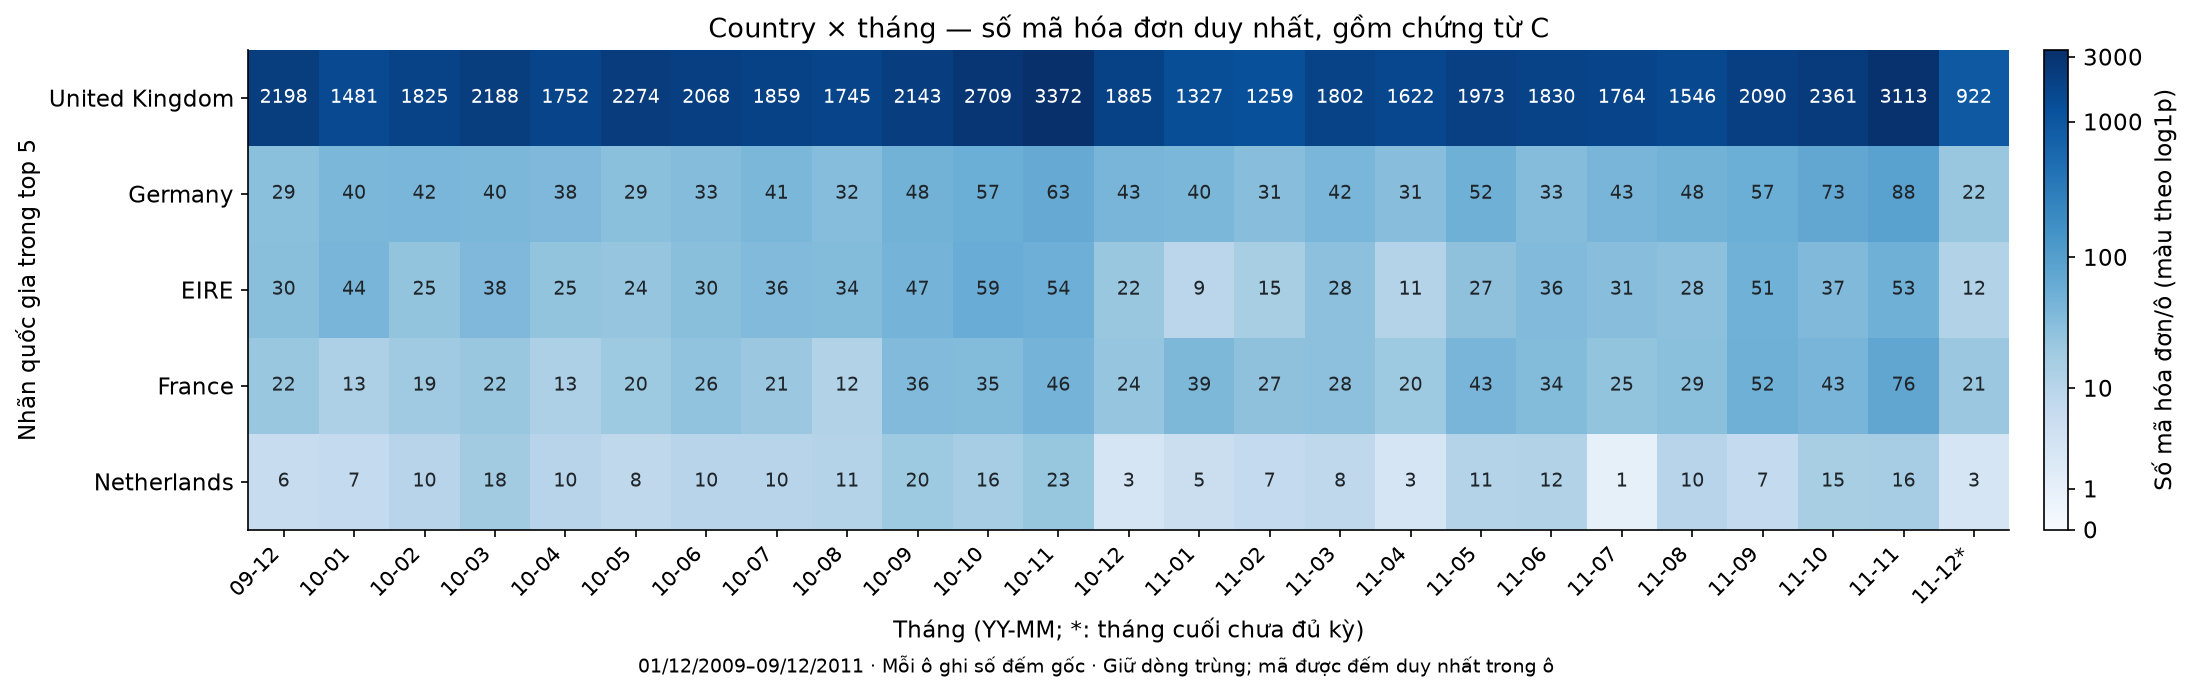

**Nhận xét.** Tháng nhiều mã nhất theo từng quốc gia: United Kingdom: 2010-11 (3,372); Germany: 2011-11 (88); EIRE: 2010-10 (59); France: 2011-11 (76); Netherlands: 2010-11 (23). Cường độ màu dùng log1p nên không đọc như tỷ lệ tuyến tính. Đỉnh từng quốc gia có thể khác nhau; mức tăng/giảm chưa xác định nguyên nhân và tháng cuối không so trực tiếp với tháng đầy đủ.

In [24]:
country_month_eligible = country_eligible & eda['InvoiceDateParsed'].notna()
calendar_all = pd.period_range(date_min.to_period('M'), date_max.to_period('M'), freq='M')
country_month_matrix = (eda.loc[country_month_eligible].assign(Month=lambda f: f['InvoiceDateParsed'].dt.to_period('M'))
                        .groupby(['CountryKey', 'Month'])['InvoiceKey'].nunique().unstack('Month', fill_value=0)
                        .reindex(index=analysis_countries, columns=calendar_all).fillna(0).astype(int))
country_month_peaks = pd.DataFrame([{'Country': country, 'Tháng nhiều mã nhất': str(row.idxmax()),
                                   'Số mã trong tháng đỉnh': int(row.max())}
                                  for country, row in country_month_matrix.iterrows()])
show_table(country_month_peaks)
fig, ax = plt.subplots(figsize=(14.5, 4.5), layout='constrained')
heat_values = np.log1p(country_month_matrix.to_numpy())
heat = ax.imshow(heat_values, cmap='Blues', aspect='auto', vmin=0)
month_labels = [str(m)[2:] + ('*' if m.end_time.normalize() > date_max.normalize() else '') for m in calendar_all]
ax.set_xticks(np.arange(len(calendar_all)), month_labels, rotation=45, ha='right', fontsize=10)
ax.set_yticks(np.arange(len(analysis_countries)), analysis_countries)
for i in range(len(analysis_countries)):
    for j in range(len(calendar_all)):
        ax.text(j, i, str(country_month_matrix.iat[i, j]), ha='center', va='center', fontsize=9,
                color='white' if heat_values[i, j] > heat_values.max() * 0.6 else '#20252A')
colorbar = fig.colorbar(heat, ax=ax, pad=0.02)
colorbar_ticks = [v for v in [0, 1, 10, 100, 1000, 3000] if np.log1p(v) <= heat_values.max()]
colorbar.set_ticks(np.log1p(colorbar_ticks), labels=[str(v) for v in colorbar_ticks])
colorbar.set_label('Số mã hóa đơn/ô (màu theo log1p)')
ax.set(title='Country × tháng — số mã hóa đơn duy nhất, gồm chứng từ C',
       xlabel='Tháng (YY-MM; *: tháng cuối chưa đủ kỳ)', ylabel='Nhãn quốc gia trong top 5')
fig.supxlabel(f'{date_min:%d/%m/%Y}–{date_max:%d/%m/%Y} · Mỗi ô ghi số đếm gốc · Giữ dòng trùng; mã được đếm duy nhất trong ô', fontsize=9)
show_figure(fig, 'invoices_by_country_month_heatmap.png')
note('Tháng nhiều mã nhất theo từng quốc gia: ' + '; '.join(
     f"{row['Country']}: {row['Tháng nhiều mã nhất']} ({row['Số mã trong tháng đỉnh']:,})"
     for row in country_month_peaks.to_dict('records')) + '. '
     'Cường độ màu dùng log1p nên không đọc như tỷ lệ tuyến tính. Đỉnh từng quốc gia có thể khác nhau; '
     'mức tăng/giảm chưa xác định nguyên nhân và tháng cuối không so trực tiếp với tháng đầy đủ.')

## 7. Phân tích hành vi mua

### 7.1. Số hóa đơn theo tháng — giữ hình hiện có

**Câu hỏi:** số mã chứng từ thay đổi thế nào theo thời gian quan sát?

**Phạm vi/cách tính:** `nunique(InvoiceKey)` từng tháng trên toàn bộ sheet, gồm C,
âm, trùng và thiếu Customer ID. Loại khỏi phép nhóm các dòng thiếu ngày/mã, báo số dòng đó.
Tháng cuối chưa đầy đủ. Số mã chứng từ chưa phải số đơn mua thành công.

In [25]:
time_eligible = eda['InvoiceDateParsed'].notna() & eda['InvoiceKey'].notna()
monthly = (eda.loc[time_eligible].assign(Month=lambda frame: frame['InvoiceDateParsed'].dt.to_period('M'))
           .groupby('Month')['InvoiceKey'].nunique().sort_index().rename('Số hóa đơn duy nhất').to_frame())
calendar = pd.period_range(date_min.to_period('M'), date_max.to_period('M'), freq='M')
monthly = monthly.reindex(calendar)
monthly.index.name = 'Tháng'
monthly['Trạng thái'] = ['Ngoài phạm vi đủ tháng' if (month.start_time < date_min.normalize() or month.end_time.normalize() > date_max.normalize())
                        else 'Trong phạm vi quan sát cả tháng' for month in monthly.index]
monthly_view = monthly.reset_index()
monthly_view['Tháng'] = monthly_view['Tháng'].astype(str)
show_table(monthly_view)
monthly_reconciliation = int(monthly['Số hóa đơn duy nhất'].sum()) - n_invoices
note(f'Có {vn_int((~time_eligible).sum())} dòng không đủ ngày/mã hóa đơn để nhóm tháng '
     f'(ngày thiếu {date_missing}, ngày lỗi {date_invalid}). '
     f'{len(multi_month)} mã xuất hiện ở nhiều tháng; tổng các số đếm tháng trừ tổng mã duy nhất là {monthly_reconciliation}. '
     'Ô không có quan sát nếu có được giữ NaN, không tự diễn giải thành tháng kinh doanh bằng 0.')

Tháng,Số hóa đơn duy nhất,Trạng thái
2009-12,2330,Trong phạm vi quan sát cả tháng
2010-01,1633,Trong phạm vi quan sát cả tháng
2010-02,1969,Trong phạm vi quan sát cả tháng
2010-03,2367,Trong phạm vi quan sát cả tháng
2010-04,1892,Trong phạm vi quan sát cả tháng
2010-05,2418,Trong phạm vi quan sát cả tháng
2010-06,2216,Trong phạm vi quan sát cả tháng
2010-07,2017,Trong phạm vi quan sát cả tháng
2010-08,1877,Trong phạm vi quan sát cả tháng
2010-09,2375,Trong phạm vi quan sát cả tháng


**Nhận xét.** Có 0 dòng không đủ ngày/mã hóa đơn để nhóm tháng (ngày thiếu 0, ngày lỗi 0). 0 mã xuất hiện ở nhiều tháng; tổng các số đếm tháng trừ tổng mã duy nhất là 0. Ô không có quan sát nếu có được giữ NaN, không tự diễn giải thành tháng kinh doanh bằng 0.

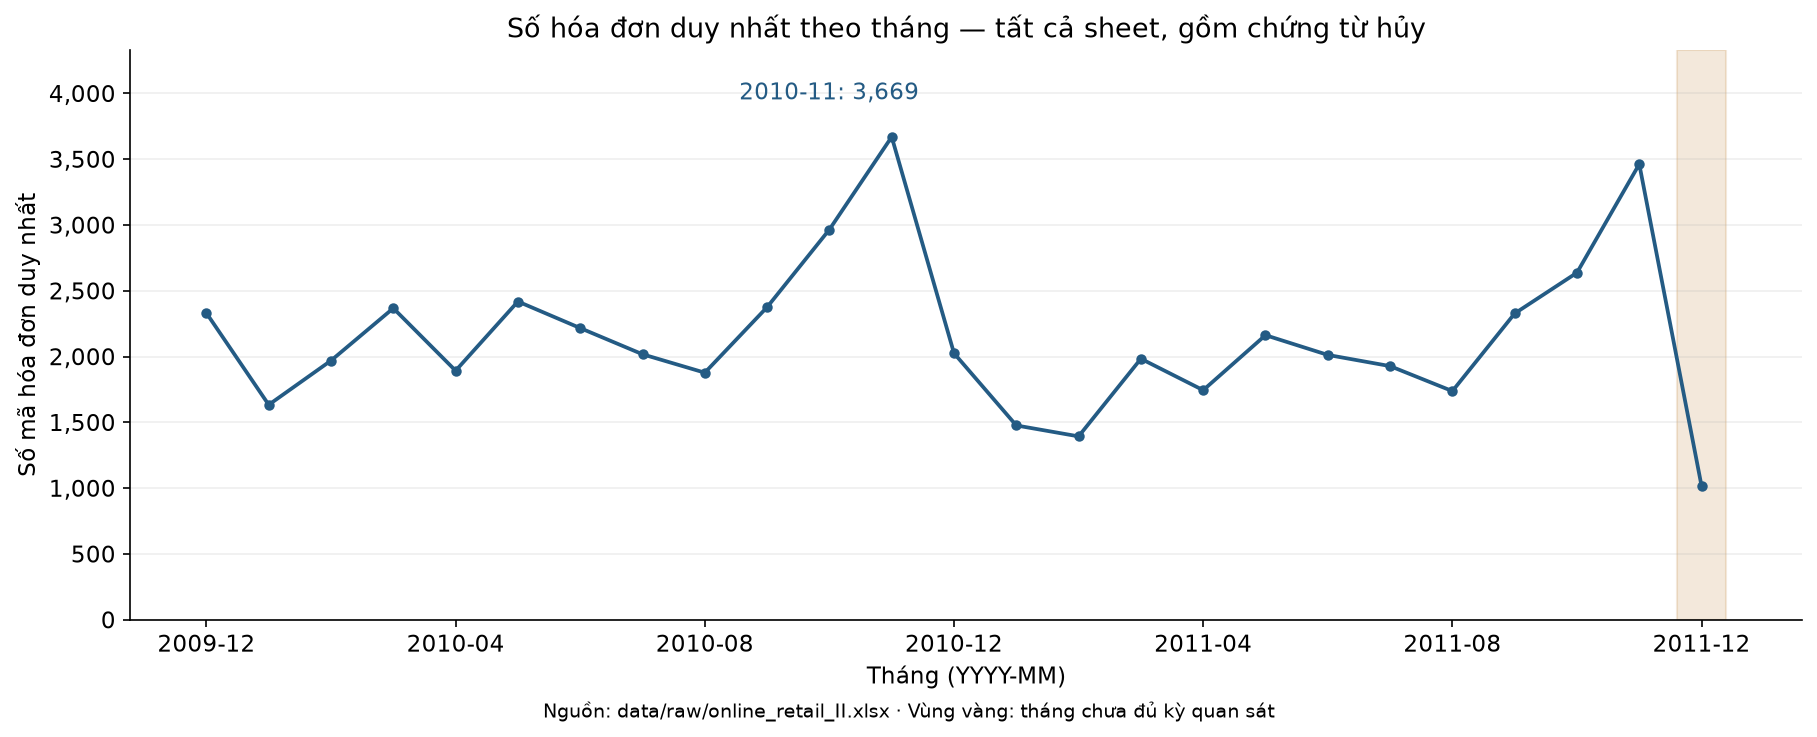

**Nhận xét.** Tháng nhiều mã hóa đơn nhất là 2010-11 (3.669); trong các tháng nằm trọn phạm vi quan sát, thấp nhất là 2011-02 (1.393). Biến động tháng kề nhau lớn nhất theo tỷ lệ là 2011-03 (+42.35%), giảm mạnh nhất là 2010-12 (-44.81%). Tháng cuối chỉ có dữ liệu đến 09/12/2011, nên không so trực tiếp với tháng đầy đủ. Đây là biến động quan sát được, chưa chứng minh nguyên nhân hoặc tính mùa vụ lặp lại.

In [26]:
fig, ax = plt.subplots(figsize=(12, 4.8), layout='constrained')
x_positions = np.arange(len(monthly))
counts = monthly['Số hóa đơn duy nhất']
ax.plot(x_positions, counts, color=BLUE, marker='o', markersize=4, linewidth=1.8)
for position, status in enumerate(monthly['Trạng thái']):
    if status == 'Ngoài phạm vi đủ tháng':
        ax.axvspan(position - 0.4, position + 0.4, color=GOLD, alpha=0.15)
ticks = np.linspace(0, len(monthly) - 1, min(7, len(monthly)), dtype=int).tolist()
ax.set_xticks(ticks, [str(monthly.index[position]) for position in ticks])
ax.set(xlabel='Tháng (YYYY-MM)', ylabel='Số mã hóa đơn duy nhất', ylim=(0, counts.max() * 1.18),
       title='Số hóa đơn duy nhất theo tháng — tất cả sheet, gồm chứng từ hủy')
ax.yaxis.set_major_formatter(StrMethodFormatter('{x:,.0f}'))
ax.grid(axis='y', alpha=0.2)
peak_month = counts.idxmax()
peak_position = monthly.index.get_loc(peak_month)
ax.annotate(f'{peak_month}: {counts.max():,.0f}', xy=(peak_position, counts.max()),
            xytext=(-30, 18), textcoords='offset points', ha='center', color=BLUE)
fig.supxlabel('Nguồn: data/raw/online_retail_II.xlsx · Vùng vàng: tháng chưa đủ kỳ quan sát', fontsize=9)
show_figure(fig, 'invoices_by_month.png')

complete_months = monthly[monthly['Trạng thái'].eq('Trong phạm vi quan sát cả tháng')]
complete_counts = complete_months['Số hóa đơn duy nhất']
monthly_changes = complete_counts.pct_change(fill_method=None).dropna()
note(f'Tháng nhiều mã hóa đơn nhất là {peak_month} ({vn_int(counts.max())}); '
     f'trong các tháng nằm trọn phạm vi quan sát, thấp nhất là {complete_counts.idxmin()} ({vn_int(complete_counts.min())}). '
     f'Biến động tháng kề nhau lớn nhất theo tỷ lệ là {monthly_changes.idxmax()} ({monthly_changes.max():+.2%}), '
     f'giảm mạnh nhất là {monthly_changes.idxmin()} ({monthly_changes.min():+.2%}). '
     f'Tháng cuối chỉ có dữ liệu đến {date_max:%d/%m/%Y}, nên không so trực tiếp với tháng đầy đủ. '
     'Đây là biến động quan sát được, chưa chứng minh nguyên nhân hoặc tính mùa vụ lặp lại.')

### 7.2. Giá trị giao dịch theo tháng

**Câu hỏi:** số dòng, số chứng từ và tổng giá trị đại số có biến động giống nhau không?

**Phạm vi/cách tính:** tổng `LineValue` của mọi dòng có ngày hợp lệ, giữ trùng/hủy/âm,
đồng thời tách phần giá trị từ dòng C (là một tập con, không cộng hai đường với nhau).
Bảng dùng GBP, hình dùng **triệu GBP**. Đây là tổng đại số nguồn, chưa phải doanh thu thuần.

Month,Rows,Invoices,SignedValueGBP,CValueGBP
2009-12,45228,2330,"799,847.11","-25,838.65"
2010-01,31555,1633,"624,032.89","-28,675.61"
2010-02,29388,1969,"533,091.43","-20,248.31"
2010-03,41511,2367,"765,848.76","-67,721.37"
2010-04,34057,1892,"590,580.43","-37,354.20"
2010-05,35323,2418,"615,322.83","-44,536.03"
2010-06,39983,2216,"679,786.61","-72,483.53"
2010-07,33383,2017,"575,236.36","-31,444.79"
2010-08,33306,1877,"656,776.34","-40,498.57"
2010-09,42091,2375,"853,650.43","-70,682.58"


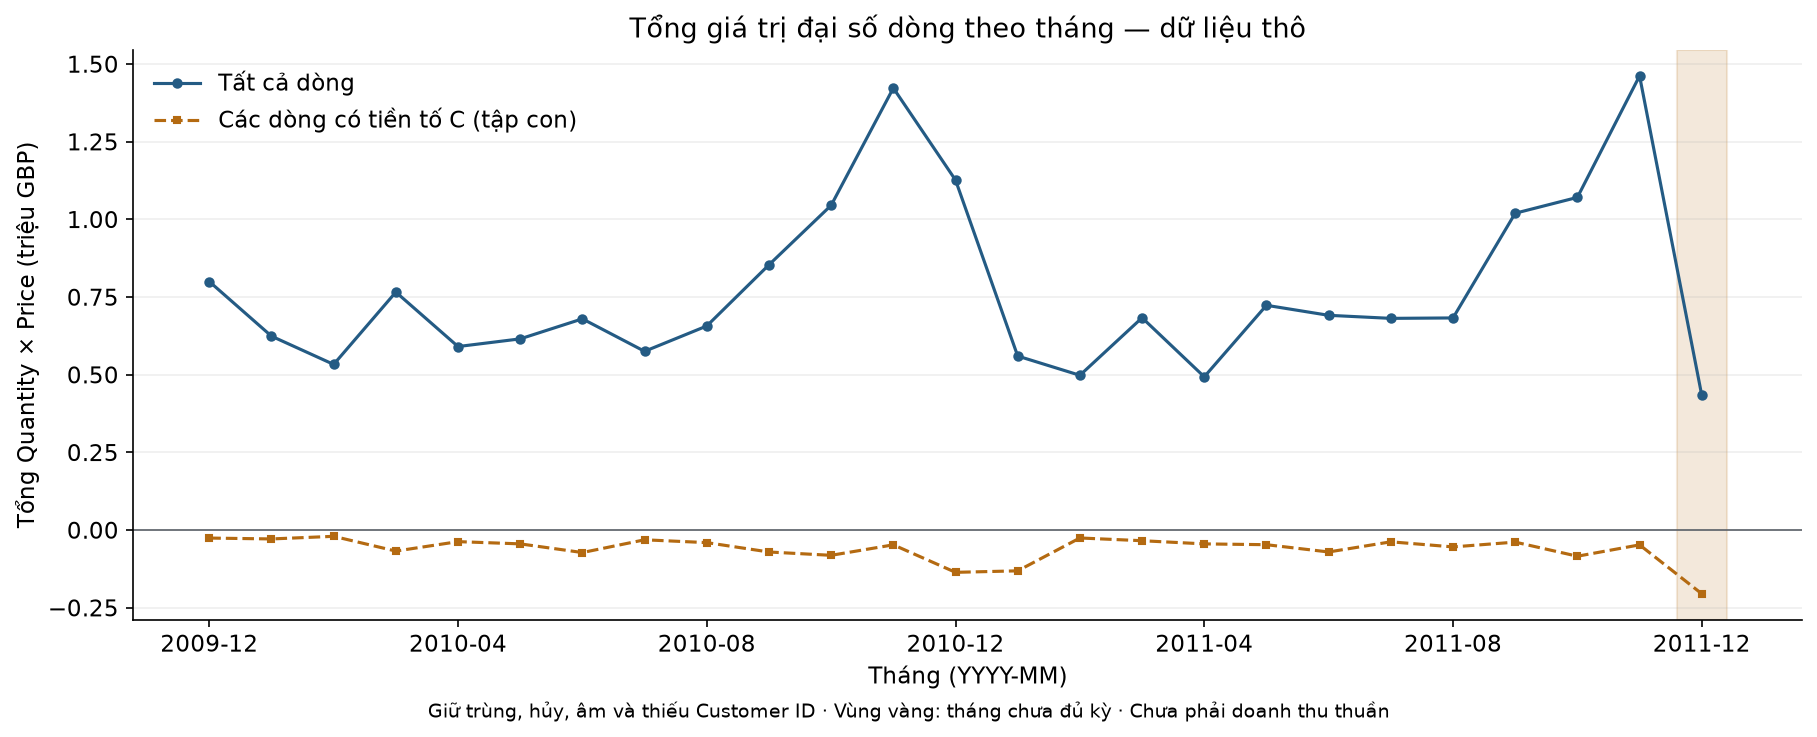

**Nhận xét.** Tổng đại số nguồn trên các dòng có ngày hợp lệ là 19,287,250.57 GBP. Tháng có tổng lớn nhất là 2011-11 (1,461,756.25 GBP), còn tháng nhiều mã hóa đơn nhất là 2010-11. Số mã và tổng giá trị đo hai khía cạnh khác nhau. Dòng trùng và bút toán có thể làm thay đổi tổng; tháng chưa đủ kỳ không dùng làm bằng chứng suy giảm hành vi mua.

In [27]:
value_time_eligible = eda['InvoiceDateParsed'].notna()
value_time_data = eda.loc[value_time_eligible].assign(Month=lambda f: f['InvoiceDateParsed'].dt.to_period('M'))
monthly_value = value_time_data.groupby('Month').agg(
    Rows=('LineValue', 'size'), Invoices=('InvoiceKey', 'nunique'),
    SignedValueGBP=('LineValue', lambda v: v.sum(min_count=1)))
monthly_c_value = (value_time_data.loc[cancelled.loc[value_time_data.index]]
                   .groupby('Month')['LineValue'].sum(min_count=1))
monthly_value['CValueGBP'] = monthly_c_value.reindex(monthly_value.index, fill_value=0)
monthly_value = monthly_value.reindex(calendar)
monthly_value.index.name = 'Month'
show_table(monthly_value.reset_index().assign(Month=lambda f: f['Month'].astype(str)),
           {'SignedValueGBP': '{:,.2f}', 'CValueGBP': '{:,.2f}'})
fig, ax = plt.subplots(figsize=(12, 4.8), layout='constrained')
ax.plot(x_positions, monthly_value['SignedValueGBP'] / 1e6, color=BLUE, marker='o', markersize=4,
        label='Tất cả dòng')
ax.plot(x_positions, monthly_value['CValueGBP'] / 1e6, color=GOLD, marker='s', markersize=3,
        linestyle='--', label='Các dòng có tiền tố C (tập con)')
for position, status in enumerate(monthly['Trạng thái']):
    if status == 'Ngoài phạm vi đủ tháng':
        ax.axvspan(position - 0.4, position + 0.4, color=GOLD, alpha=0.15)
ax.set_xticks(ticks, [str(calendar[p]) for p in ticks])
ax.axhline(0, color=GRAY, linewidth=0.8)
ax.set(title='Tổng giá trị đại số dòng theo tháng — dữ liệu thô', xlabel='Tháng (YYYY-MM)',
       ylabel='Tổng Quantity × Price (triệu GBP)')
ax.legend(frameon=False, loc='upper left')
ax.grid(axis='y', alpha=0.2)
fig.supxlabel('Giữ trùng, hủy, âm và thiếu Customer ID · Vùng vàng: tháng chưa đủ kỳ · Chưa phải doanh thu thuần', fontsize=9)
show_figure(fig, 'signed_line_value_by_month.png')
value_peak = monthly_value['SignedValueGBP'].idxmax()
note(f'Tổng đại số nguồn trên các dòng có ngày hợp lệ là {monthly_value["SignedValueGBP"].sum():,.2f} GBP. '
     f'Tháng có tổng lớn nhất là {value_peak} ({monthly_value.loc[value_peak, "SignedValueGBP"]:,.2f} GBP), '
     f'còn tháng nhiều mã hóa đơn nhất là {peak_month}. '
     'Số mã và tổng giá trị đo hai khía cạnh khác nhau. Dòng trùng và bút toán có thể làm thay đổi tổng; '
     'tháng chưa đủ kỳ không dùng làm bằng chứng suy giảm hành vi mua.')

### 7.3. Thứ trong tuần và giờ ghi nhận chứng từ

**Câu hỏi:** các chứng từ được ghi nhận nhiều vào thứ/giờ nào?

**Phạm vi/cách tính:** mỗi InvoiceKey có ngày hợp lệ chỉ đếm một lần;
với mã có nhiều thời điểm, tạm dùng **thời điểm ghi nhận sớm nhất**.
Giữ cả C. Các ô 0 chỉ biểu thị không có chứng từ được quan sát;
giờ nguồn không có múi giờ, không coi là múi giờ của khách hàng.

C:\Users\atnn2\AppData\Local\Temp\ipykernel_16956\2410207980.py:2: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  weekday_counts = invoice_calendar.dt.dayofweek.value_counts().reindex(range(7), fill_value=0).sort_index()


Thứ,Số mã hóa đơn
Thứ 2,8595
Thứ 3,10299
Thứ 4,9597
Thứ 5,11335
Thứ 6,8505
Thứ 7,32
Chủ nhật,5265


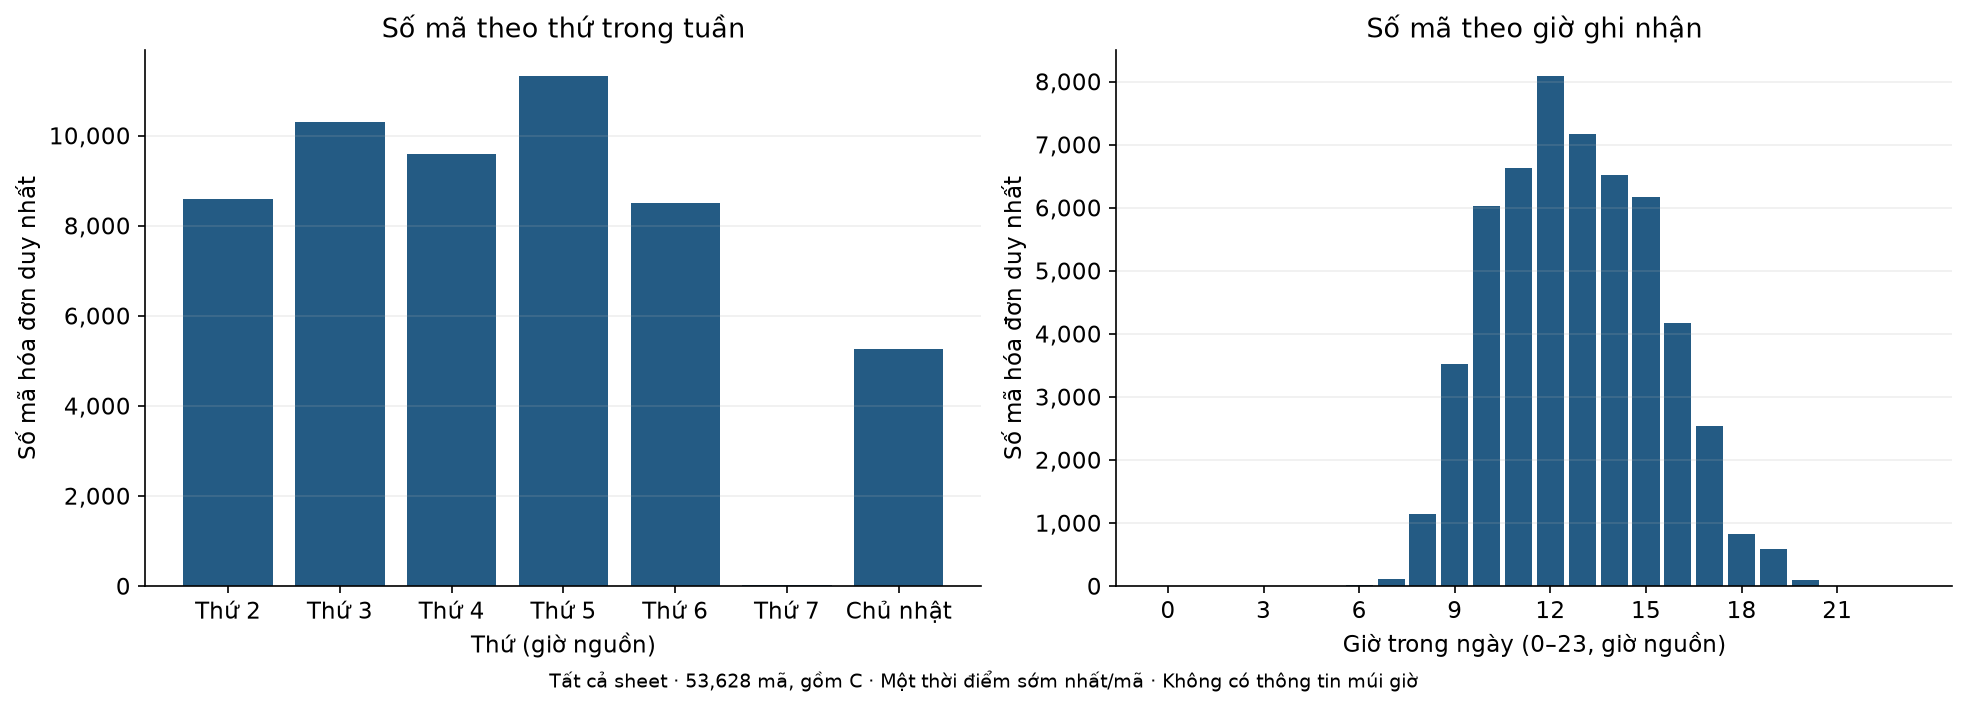

**Nhận xét.** Thứ 5 có nhiều mã nhất (11.335); giờ 12:00–12:59 có 8.097 mã. Có 83 mã có nhiều thời điểm và được quy về mốc sớm nhất. Đây là thời điểm ghi nhận trong hệ thống; chưa đủ bằng chứng về giờ khách hàng đặt mua hoặc lịch mở cửa.

In [28]:
invoice_calendar = (eda.loc[time_eligible].groupby('InvoiceKey')['InvoiceDateParsed'].min())
weekday_counts = invoice_calendar.dt.dayofweek.value_counts().reindex(range(7), fill_value=0).sort_index()
hour_counts = invoice_calendar.dt.hour.value_counts().reindex(range(24), fill_value=0).sort_index()
weekday_names = ['Thứ 2', 'Thứ 3', 'Thứ 4', 'Thứ 5', 'Thứ 6', 'Thứ 7', 'Chủ nhật']
show_table(pd.DataFrame({'Thứ': weekday_names, 'Số mã hóa đơn': weekday_counts.to_numpy()}))
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), layout='constrained')
axes[0].bar(weekday_names, weekday_counts, color=BLUE)
axes[0].set(title='Số mã theo thứ trong tuần', xlabel='Thứ (giờ nguồn)', ylabel='Số mã hóa đơn duy nhất')
axes[1].bar(hour_counts.index, hour_counts, color=BLUE, width=0.85)
axes[1].set_xticks(range(0, 24, 3))
axes[1].set(title='Số mã theo giờ ghi nhận', xlabel='Giờ trong ngày (0–23, giờ nguồn)', ylabel='Số mã hóa đơn duy nhất')
for ax in axes:
    ax.yaxis.set_major_formatter(StrMethodFormatter('{x:,.0f}'))
    ax.grid(axis='y', alpha=0.2)
fig.supxlabel(f'Tất cả sheet · {len(invoice_calendar):,} mã, gồm C · Một thời điểm sớm nhất/mã · Không có thông tin múi giờ', fontsize=9)
show_figure(fig, 'invoices_by_weekday_hour.png')
note(f'{weekday_names[int(weekday_counts.idxmax())]} có nhiều mã nhất ({vn_int(weekday_counts.max())}); '
     f'giờ {hour_counts.idxmax():02d}:00–{hour_counts.idxmax():02d}:59 có {vn_int(hour_counts.max())} mã. '
     f'Có {vn_int(invoice_date_counts.gt(1).sum())} mã có nhiều thời điểm và được quy về mốc sớm nhất. '
     'Đây là thời điểm ghi nhận trong hệ thống; chưa đủ bằng chứng về giờ khách hàng đặt mua hoặc lịch mở cửa.')

### 7.4. Khảo sát tạm thời theo khách hàng — chưa phải RFM chính thức

**Câu hỏi:** trong tập dòng mua ứng viên, khách hàng có bao nhiêu hóa đơn được quan sát,
tổng giá trị dương và số ngày từ lần ghi nhận gần nhất như thế nào?

**Phạm vi/cách tính — các giả định khảo sát, cần trao đổi với Thuận:**

1. Chỉ giữ ở **bản khảo sát trong bộ nhớ** những dòng có Customer ID hợp lệ về hình thức,
   ngày đọc được, InvoiceKey đúng 6 chữ số (do đó không có tiền tố C), Quantity > 0, Price > 0,
   LineValue hữu hạn; loại khỏi phép tổng hợp mã hóa đơn gắn nhiều khách hàng không thiếu nếu có.
2. **Giữ mọi dòng trùng, chồng lấn, cực trị và mã hàng dịch vụ**; chưa đối trừ hoàn/hủy.
   Tổng giá trị dương có thể bị tăng do bản sao. Một hóa đơn chỉ có một phần dòng đủ điều kiện
   vẫn được đếm; không khẳng định đây là giỏ hàng đầy đủ.
3. Số hóa đơn ứng viên = `nunique(InvoiceKey)` theo Customer ID, không phải số dòng.
   Giá trị ứng viên = tổng LineValue của các dòng thỏa điều kiện, chưa phải Monetary chính thức.
4. Ngày tham chiếu tạm = ngày sau ngày cuối nguồn, lúc 00:00. Số ngày tính theo **ngày lịch**
   từ lần ghi nhận ứng viên gần nhất; không tính kỳ dự báo. Bảng ghi ngày tham chiếu thực tế.
5. Chỉ khảo sát khách hàng có ít nhất một dòng thỏa điều kiện. Không đại diện các khách hàng
   thiếu mã, chỉ có hoàn/hủy hoặc không có dòng ứng viên. Không gắn nhãn VIP/phân khúc.

Bảng ghi số dòng bị loại **theo từng bước tích lũy**, số mã hóa đơn và số khách hàng còn lại.
Toàn bộ bảng/hình này dùng dữ liệu thực tế theo các điều kiện trên, không phải kiểm thử dữ liệu nhỏ.
Không ghi bảng đặc trưng hay dữ liệu tiền xử lý ra đĩa.

In [29]:
candidate_steps = [
    ('Toàn bộ dữ liệu thô', pd.Series(True, index=eda.index)),
    ('Customer ID hợp lệ về hình thức', valid_customer),
    ('Có ngày phân tích được', eda['InvoiceDateParsed'].notna()),
    ('Mã hóa đơn đúng 6 chữ số, không C', eda['InvoiceKey'].str.fullmatch(r'\d{6}', na=False)),
    ('Quantity > 0, Price > 0, LineValue hữu hạn',
     eda['Quantity'].gt(0) & eda['Price'].gt(0) & np.isfinite(eda['LineValue'])),
    ('Không có mâu thuẫn nhiều Customer ID/mã hóa đơn', ~eda['InvoiceKey'].isin(multi_customer.index)),
]
candidate_mask = pd.Series(True, index=eda.index)
scope_records = []
previous_rows = len(eda)
for label, condition in candidate_steps:
    candidate_mask &= condition.fillna(False)
    selected = eda.loc[candidate_mask]
    scope_records.append({'Bước tích lũy': label, 'Dòng còn lại': len(selected),
                          'Dòng giảm ở bước này': previous_rows - len(selected),
                          'Mã hóa đơn': selected['InvoiceKey'].nunique(),
                          'Khách hàng có mã hợp lệ': selected.loc[valid_customer.loc[selected.index], 'Customer ID'].nunique()})
    previous_rows = len(selected)
candidate_scope = pd.DataFrame(scope_records)
show_table(candidate_scope)
candidate = eda.loc[candidate_mask].copy()
if candidate.empty:
    raise ValueError('Không có dòng mua ứng viên để khảo sát; cần xem lại nguồn/giả định.')
customer_survey = candidate.groupby('Customer ID').agg(
    ObservedRows=('InvoiceKey', 'size'), ObservedInvoices=('InvoiceKey', 'nunique'),
    PositiveLineValueGBP=('LineValue', 'sum'), FirstObserved=('InvoiceDateParsed', 'min'),
    LastObserved=('InvoiceDateParsed', 'max'))
reference_date = date_max.normalize() + pd.Timedelta(days=1)
customer_survey['DaysSinceLastCandidate'] = (reference_date - customer_survey['LastObserved'].dt.normalize()).dt.days
customer_survey['ValuePerCandidateInvoiceGBP'] = customer_survey['PositiveLineValueGBP'] / customer_survey['ObservedInvoices']
print('Ngày tham chiếu tạm (ngày lịch):', reference_date.strftime('%Y-%m-%d'))
customer_metrics = ['ObservedRows', 'ObservedInvoices', 'PositiveLineValueGBP',
                    'DaysSinceLastCandidate', 'ValuePerCandidateInvoiceGBP']
survey_description = customer_survey[customer_metrics].describe(percentiles=[0.25, 0.5, 0.75, 0.99]).T
show_table(survey_description.reset_index(names='Chỉ số khảo sát'), {c: '{:,.2f}' for c in survey_description.columns})
single_invoice_customers = int(customer_survey['ObservedInvoices'].eq(1).sum())
repeat_invoice_customers = int(customer_survey['ObservedInvoices'].gt(1).sum())
survey_duplicate_excess = int(candidate.duplicated(subset=original_columns).sum())
note(f'Tập khảo sát có {vn_int(len(candidate))} dòng ({len(candidate) / n_rows:.2%} dòng thô), '
     f'{vn_int(candidate["InvoiceKey"].nunique())} mã hóa đơn và {vn_int(len(customer_survey))} khách hàng. '
     f'{vn_int(single_invoice_customers)} khách hàng có 1 mã; {vn_int(repeat_invoice_customers)} có trên 1 mã '
     f'({repeat_invoice_customers / len(customer_survey):.2%} khách hàng trong tập khảo sát). '
     f'Vẫn còn {vn_int(survey_duplicate_excess)} dòng trùng dư; tổng {candidate["LineValue"].sum():,.2f} GBP '
     'chưa đối trừ hủy/hoàn và chưa phải doanh thu/Monetary đã làm sạch.')

Bước tích lũy,Dòng còn lại,Dòng giảm ở bước này,Mã hóa đơn,Khách hàng có mã hợp lệ
Toàn bộ dữ liệu thô,1067371,0,53628,5942
Customer ID hợp lệ về hình thức,824364,243007,44876,5942
Có ngày phân tích được,824364,0,44876,5942
"Mã hóa đơn đúng 6 chữ số, không C",805620,18744,36975,5881
"Quantity > 0, Price > 0, LineValue hữu hạn",805549,71,36969,5878
Không có mâu thuẫn nhiều Customer ID/mã hóa đơn,805549,0,36969,5878


Ngày tham chiếu tạm (ngày lịch): 2011-12-10


Chỉ số khảo sát,count,mean,std,min,25%,50%,75%,99%,max
ObservedRows,"5,878.00",137.04,353.82,1.00,21.00,53.00,142.00,"1,116.23","12,890.00"
ObservedInvoices,"5,878.00",6.29,13.01,1.00,1.00,3.00,7.00,46.00,398.00
PositiveLineValueGBP,"5,878.00","3,018.62","14,737.73",2.95,348.76,898.91,"2,307.09","29,730.42","608,821.65"
DaysSinceLastCandidate,"5,878.00",201.87,209.35,1.00,26.00,96.00,380.00,727.00,739.00
ValuePerCandidateInvoiceGBP,"5,878.00",391.73,"1,215.07",2.95,181.65,285.07,420.57,"1,994.99","84,236.25"


**Nhận xét.** Tập khảo sát có 805.549 dòng (75.47% dòng thô), 36.969 mã hóa đơn và 5.878 khách hàng. 1.623 khách hàng có 1 mã; 4.255 có trên 1 mã (72.39% khách hàng trong tập khảo sát). Vẫn còn 26.124 dòng trùng dư; tổng 17,743,429.18 GBP chưa đối trừ hủy/hoàn và chưa phải doanh thu/Monetary đã làm sạch.

#### 7.4.1. Phân phối số hóa đơn và giá trị trong tập khảo sát

**Câu hỏi:** các chỉ số khảo sát tập trung ở đâu và có đuôi lớn không?

**Phạm vi/cách tính:** toàn bộ khách hàng trong mục 7.4, mỗi người một quan sát.
Hai trục x thang log, bin theo khoảng log (chiều rộng không đều trên thang gốc),
trục y số khách hàng/bin. Không cắt ngoại lai hoặc lấy mẫu.

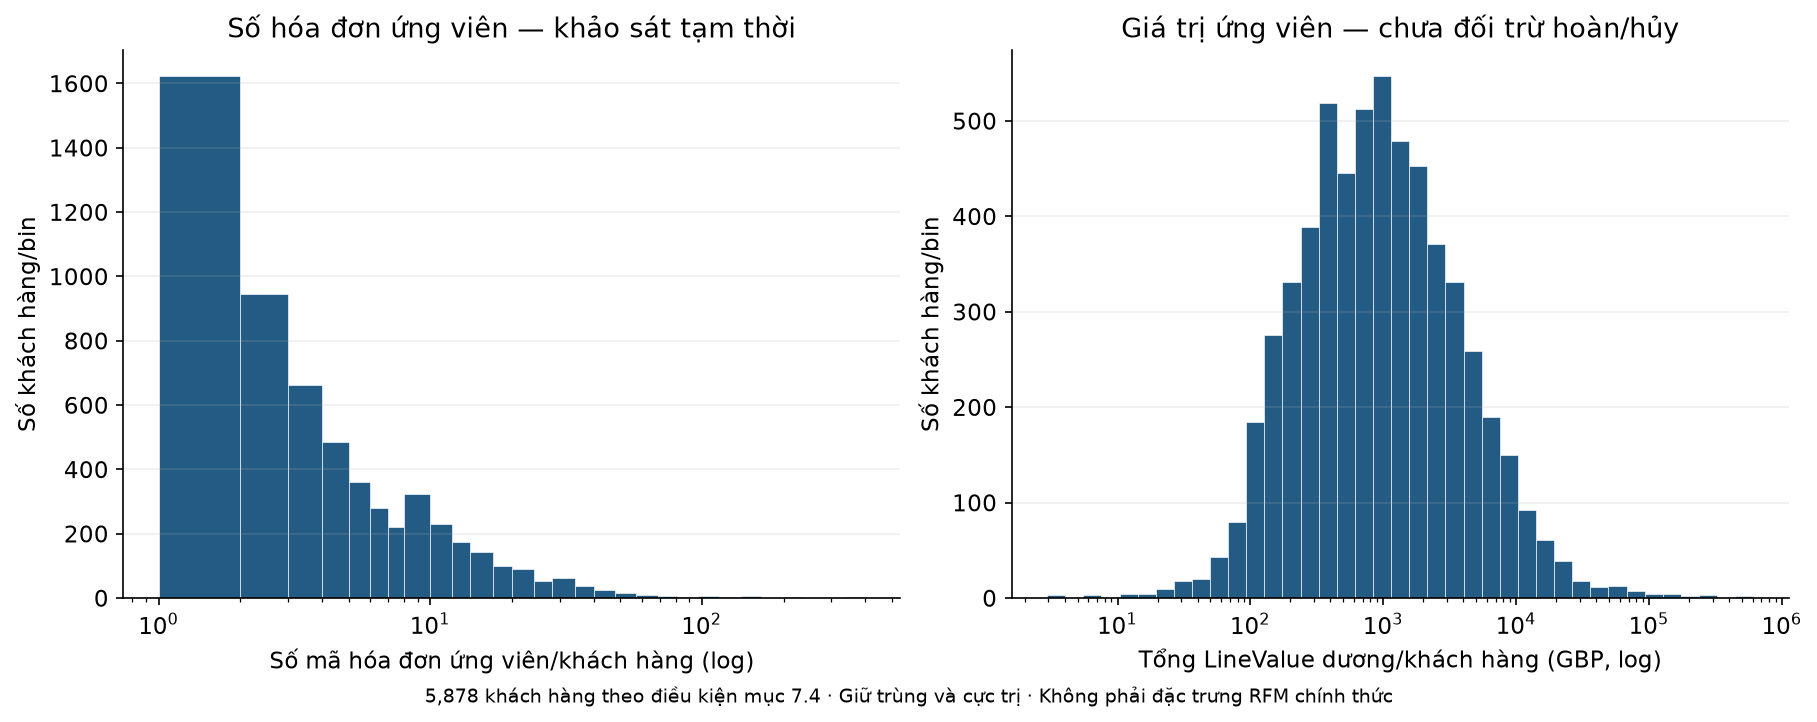

**Nhận xét.** Trung vị số hóa đơn ứng viên = 3; P99 = 46; trung vị tổng giá trị dương = 898.91 GBP; P99 = 29,730.42 GBP. Tại ngày tham chiếu 10/12/2011, trung vị số ngày từ lần ghi nhận ứng viên gần nhất là 96. Đây là đặc điểm của tập khảo sát có điều kiện; không gọi khách hàng ít giao dịch là đã rời bỏ và không suy ra giá trị tương lai từ lịch sử này.

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.7), layout='constrained')
invoice_bins = np.unique(np.round(np.geomspace(1, customer_survey['ObservedInvoices'].max() + 1, 35)))
axes[0].hist(customer_survey['ObservedInvoices'], bins=invoice_bins, color=BLUE, edgecolor='white', linewidth=0.3)
axes[0].set(xlabel='Số mã hóa đơn ứng viên/khách hàng (log)', ylabel='Số khách hàng/bin',
            title='Số hóa đơn ứng viên — khảo sát tạm thời')
positive_values = customer_survey['PositiveLineValueGBP']
value_bins = np.geomspace(positive_values.min(), positive_values.max(), 40)
value_bins[0], value_bins[-1] = positive_values.min(), positive_values.max()
axes[1].hist(positive_values, bins=value_bins, color=BLUE, edgecolor='white', linewidth=0.3)
axes[1].set(xlabel='Tổng LineValue dương/khách hàng (GBP, log)', ylabel='Số khách hàng/bin',
            title='Giá trị ứng viên — chưa đối trừ hoàn/hủy')
for ax in axes:
    ax.set_xscale('log')
    ax.grid(axis='y', alpha=0.2)
fig.supxlabel(f'{len(customer_survey):,} khách hàng theo điều kiện mục 7.4 · Giữ trùng và cực trị · Không phải đặc trưng RFM chính thức', fontsize=9)
show_figure(fig, 'customer_candidate_behavior_distributions.png')
note(f'Trung vị số hóa đơn ứng viên = {customer_survey["ObservedInvoices"].median():g}; '
     f'P99 = {customer_survey["ObservedInvoices"].quantile(0.99):g}; '
     f'trung vị tổng giá trị dương = {positive_values.median():,.2f} GBP; P99 = {positive_values.quantile(0.99):,.2f} GBP. '
     f'Tại ngày tham chiếu {reference_date:%d/%m/%Y}, trung vị số ngày từ lần ghi nhận ứng viên gần nhất là '
     f'{customer_survey["DaysSinceLastCandidate"].median():g}. '
     'Đây là đặc điểm của tập khảo sát có điều kiện; không gọi khách hàng ít giao dịch là đã rời bỏ '
     'và không suy ra giá trị tương lai từ lịch sử này.')

## 8. Kết luận, hạn chế và bàn giao

### 8.1. Phát hiện từ các kết quả đã tính

**Câu hỏi:** bằng chứng EDA hỗ trợ những nhận định nào trước khi tạo đặc trưng?

**Phạm vi/cách tính:** phần dưới lấy số từ biến đã thực thi, phân biệt toàn bộ nguồn
với tập khảo sát tạm thời; không đưa kết quả mô hình chưa chạy vào kết luận.

In [31]:
note(f'Dữ liệu gồm {vn_int(n_rows)} dòng, {len(original_columns)} cột nguồn từ {len(sheet_names)} sheet '
     f'({", ".join(sheet_names)}), giai đoạn {date_min:%d/%m/%Y}–{date_max:%d/%m/%Y}. '
     f'Nhận diện {vn_int(n_customers)} khách hàng theo mã hợp lệ về hình thức, {vn_int(n_invoices)} mã hóa đơn và '
     f'{n_countries} nhãn quốc gia. {top_country} chiếm {top_country_share:.2%} các cặp quốc gia–hóa đơn; '
     f'tháng đỉnh là {peak_month} ({vn_int(counts.max())} hóa đơn). '
     f'Các vấn đề chính: {vn_int(customer_missing)} dòng thiếu Customer ID, {vn_int(duplicate_excess)} dòng trùng dư '
     f'(trong đó tăng thêm {vn_int(cross_sheet_excess)} khi gộp), {vn_int(n_cancel_invoices)} mã hủy, '
     f'{vn_int(eda["Quantity"].lt(0).sum())} dòng lượng âm, {vn_int(eda["Price"].le(0).sum())} dòng giá không dương. '
     'Phân phối có đuôi dài và tháng cuối chưa trọn kỳ; chưa suy diễn nguyên nhân hoặc kết quả mô hình.')

**Nhận xét.** Dữ liệu gồm 1.067.371 dòng, 8 cột nguồn từ 2 sheet (Year 2009-2010, Year 2010-2011), giai đoạn 01/12/2009–09/12/2011. Nhận diện 5.942 khách hàng theo mã hợp lệ về hình thức, 53.628 mã hóa đơn và 43 nhãn quốc gia. United Kingdom chiếm 91.57% các cặp quốc gia–hóa đơn; tháng đỉnh là 2010-11 (3.669 hóa đơn). Các vấn đề chính: 243.007 dòng thiếu Customer ID, 34.335 dòng trùng dư (trong đó tăng thêm 22.202 khi gộp), 8.292 mã hủy, 22.950 dòng lượng âm, 6.207 dòng giá không dương. Phân phối có đuôi dài và tháng cuối chưa trọn kỳ; chưa suy diễn nguyên nhân hoặc kết quả mô hình.

In [32]:
note(f'Quan hệ Quantity–Price trên dữ liệu thô có Spearman {pair_correlations.iloc[0, 3]:.4f}; '
     f'tỷ trọng mã C giữa top 5 quốc gia nằm trong khoảng {cancel_shares.min():.2f}%–{cancel_shares.max():.2f}%. '
     'Các bảng phân vị và heatmap cho phép đối chiếu cơ cấu giá trị dòng và thời điểm từng quốc gia, '
     'nhưng chưa xác định nguyên nhân. '
     f'Tập khách hàng khảo sát tạm gồm {vn_int(len(customer_survey))} khách hàng, '
     f'trong đó {repeat_invoice_customers / len(customer_survey):.2%} có trên một mã ứng viên. '
     'Các số theo khách hàng phụ thuộc điều kiện mục 7.4, không thay thế đầu ra tiền xử lý chính thức.')

**Nhận xét.** Quan hệ Quantity–Price trên dữ liệu thô có Spearman -0.3990; tỷ trọng mã C giữa top 5 quốc gia nằm trong khoảng 8.40%–27.95%. Các bảng phân vị và heatmap cho phép đối chiếu cơ cấu giá trị dòng và thời điểm từng quốc gia, nhưng chưa xác định nguyên nhân. Tập khách hàng khảo sát tạm gồm 5.878 khách hàng, trong đó 72.39% có trên một mã ứng viên. Các số theo khách hàng phụ thuộc điều kiện mục 7.4, không thay thế đầu ra tiền xử lý chính thức.

### 8.2. Nội dung trao đổi với Thuận trước khi tạo đặc trưng

| Nội dung | Ảnh hưởng đến RFM/phân cụm | Quyết định cần thống nhất |
|---|---|---|
| Thiếu Customer ID | Không gán dòng về khách hàng tin cậy | Có giữ cho EDA cấp hóa đơn và loại khỏi RFM hay dùng nguồn đối chiếu? Không điền cùng một mã cho mọi dòng thiếu. |
| Trùng trong sheet và chồng lấn giữa sheet | Có thể tăng Monetary và sai Frequency nếu đếm dòng | Phân biệt bản sao với nghiệp vụ lặp; chốt khóa kiểm tra và chính sách trùng trên 8 cột nguồn. |
| Hóa đơn hủy, lượng âm và giá không dương | Có thể đảo dấu Monetary, sai khái niệm lần mua gần nhất | Chọn giao dịch mua hợp lệ, cách đối trừ hoàn trả/hủy; không gộp tất cả dấu hiệu thành một quy tắc xóa. |
| Mã hàng dịch vụ/điều chỉnh, mô tả thiếu, mã hóa đơn ngoài mẫu | Có thể lẫn bưu phí hoặc điều chỉnh với hàng hóa | Lập danh mục nghiệp vụ và xem ví dụ chứng từ trước khi lọc. |
| Mâu thuẫn quốc gia/khách hàng/thời điểm của hóa đơn nếu có | Khóa hóa đơn có thể chưa đủ nhất quán | Đối chiếu nguồn, chưa tự sửa/gán nhãn thay thế. |
| Cực trị số lượng/giá và phân phối lệch | Nhạy với khoảng cách, chuẩn hóa và số cụm | EDA v2 so sánh các phương án trên bản sao; chưa xóa/winsorize khi nhóm chưa chốt. |
| Tháng cuối chưa đầy đủ; không có múi giờ | So sánh xu hướng/RFM có thể lệch theo cửa sổ | Chốt ngày tham chiếu, cửa sổ quan sát và cách xử lý kỳ không đầy đủ. |

#### Hướng EDA v2 — chỉ đề xuất, chưa thực hiện trong Form 1

1. Kiểm tra sâu dòng trùng, các mã nghiệp vụ đặc biệt và cực trị theo hóa đơn/khách hàng.
2. So sánh độ nhạy khi xử lý hủy/hoàn trả, giá không dương và ngoại lai theo chính sách nhóm thống nhất.
3. Khảo sát phân phối RFM **sau khi** có tập giao dịch và định nghĩa R/F/M được xác nhận;
   xem log/chuẩn hóa và ảnh hưởng đến KMeans, Ward, DBSCAN theo định hướng bộ khung.
4. Nếu mở rộng sang dự đoán giá trị tương lai, cần thiết kế nhãn và chia thời gian để tránh rò rỉ;
   EDA v1 chưa xác nhận định nghĩa “khách hàng giá trị cao” hay khả năng dự báo.

### 8.3. Hạn chế dữ liệu và diễn giải

Không suy ra lợi nhuận, hành vi ngoài cửa hàng, nhân khẩu học hoặc nguyên nhân biến động từ 8 cột nguồn.
Phân cụm trên lịch sử không tự trở thành dự đoán giá trị tương lai.
Proposal đã có hướng phân công và thực nghiệm, nhưng chính sách trùng/hoàn hủy/ngoại lai, cửa sổ quan sát,
ngày tham chiếu và tiêu chí khách hàng giá trị cao cần nhóm chốt ở mức quy tắc triển khai.
Khảo sát khách hàng mục 7.4 giữ bản sao và chưa đối trừ C nên tổng giá trị có thể tăng;
khách hàng thiếu mã hoặc không có dòng ứng viên không được đại diện.
Country là nhãn nguồn, giá trị dòng không phải lợi nhuận; cuối kỳ chưa đầy đủ; không biết múi giờ.
Không suy ra chiết khấu từ tương quan Quantity–Price hoặc tỷ lệ đơn bị hủy từ tỷ lệ chứng từ C. EDA v1 không sửa các module, notebook hoặc cấu hình của thành viên khác.

### 8.4. Kiểm tra nhất quán và hình bàn giao

**Câu hỏi:** số đếm có đối chiếu được, dữ liệu gốc còn nguyên và PNG có đúng hình hiển thị không?

**Phạm vi/cách tính:** kiểm tra toàn bộ các tổng/khóa chính; đối chiếu thủ công bằng phép tính
độc lập trên 3 khách hàng được chọn xác định (mã đầu/giữa/cuối) chỉ để **kiểm thử phép tổng hợp**,
không thay tập dữ liệu dùng phân tích. Mỗi hình ghi và hiển thị cùng một chuỗi byte PNG;
kiểm tra chữ ký, kích thước, checksum và liệt kê danh sách bàn giao. Việc mở ảnh và xem bố cục
được thực hiện thêm sau khi chạy notebook. Không ghi dữ liệu trung gian/đặc trưng.

In [33]:
# Đếm độc lập bằng các tập khóa, thay cho groupby/nunique đã dùng ở trên.
assert sum(sheet_profile['Số dòng']) == len(raw)
assert n_invoices == len(set(eda['InvoiceKey'].dropna()))
assert n_cancel_invoices == len(set(eda.loc[cancelled, 'InvoiceKey'].dropna()))
assert n_country_pairs == len(set(zip(country_pairs['CountryKey'], country_pairs['InvoiceKey'])))
invoice_month_pairs = set(zip(eda.loc[time_eligible, 'InvoiceDateParsed'].dt.strftime('%Y-%m'), eda.loc[time_eligible, 'InvoiceKey']))
assert int(monthly['Số hóa đơn duy nhất'].sum()) == len(invoice_month_pairs)
assert duplicate_excess == n_rows - len(raw.drop_duplicates(subset=original_columns))
assert cross_sheet_excess >= 0
assert all(row['Dòng trong vùng'] + row['Dòng ngoài vùng'] == int(eda[row['Biến']].notna().sum()) for row in zoom_records)
assert all(np.isfinite(eda[column].dropna()).all() for column in ['Quantity', 'Price', 'LineValue'])
assert source_hash_before == sha256(DATA_PATH), 'Checksum nguồn thay đổi trong lần chạy!'
print('Các kiểm tra nhất quán đều đạt. Dữ liệu gốc giữ nguyên trong lần chạy.')
print('SHA256:', source_hash_before)

# Bản ghi tổng hợp trong bộ nhớ để đối chiếu báo cáo/bàn giao; không ghi thêm tệp dữ liệu.
evidence = {
    'source_sha256': source_hash_before, 'environment': environment,
    'sheets': sheet_profile.assign(Từ=sheet_profile['Từ'].astype(str), Đến=sheet_profile['Đến'].astype(str)).to_dict('records'),
    'rows': n_rows, 'columns': original_columns, 'customers': n_customers,
    'invoices': n_invoices, 'countries': n_countries, 'stockcodes': n_stockcodes,
    'date_min': str(date_min), 'date_max': str(date_max),
    'missing': missing.to_dict('records'), 'quality': quality_counts.to_dict('records'),
    'duplicates_excess': duplicate_excess, 'duplicates_members': duplicate_members,
    'duplicates_within_sheet': within_sheet_excess, 'duplicates_cross_sheet_excess': cross_sheet_excess,
    'cross_sheet_patterns': cross_sheet_patterns, 'shared_invoices': shared_invoice_count,
    'other_checks': other_checks.to_dict('records'), 'customer_invalid_nonmissing': customer_invalid_nonmissing,
    'date_missing': date_missing, 'date_invalid': date_invalid,
    'descriptive': descriptive.reset_index(names='Biến').to_dict('records'),
    'monthly': monthly_view.to_dict('records'),
    'country': country_table.reset_index(names='Quốc gia').to_dict('records'),
    'country_pairs': n_country_pairs, 'top_country_share': top_country_share, 'top10_share': top10_share,
    'zoom': zoom_records,
}

Các kiểm tra nhất quán đều đạt. Dữ liệu gốc giữ nguyên trong lần chạy.
SHA256: bcbe73b35f5b7babf197fb0cb983a11f5d9ff929078d4aa53d171b1f2df2e980


In [34]:
assert int(prefix_summary['Rows'].sum()) == n_rows
assert int(prefix_summary['Invoices'].sum()) == n_invoices
assert pair_hexbin_count == int(pair_mask.sum()), 'Hexbin thiếu quan sát!'
assert int(country_prefix_counts.to_numpy().sum()) == len(set(zip(
    eda.loc[country_eligible & eda['CountryKey'].isin(analysis_countries), 'CountryKey'],
    eda.loc[country_eligible & eda['CountryKey'].isin(analysis_countries), 'InvoiceKey'])))
matrix_keys = set(zip(eda.loc[country_month_eligible & eda['CountryKey'].isin(analysis_countries), 'CountryKey'],
                      eda.loc[country_month_eligible & eda['CountryKey'].isin(analysis_countries), 'InvoiceDateParsed'].dt.to_period('M'),
                      eda.loc[country_month_eligible & eda['CountryKey'].isin(analysis_countries), 'InvoiceKey']))
assert int(country_month_matrix.to_numpy().sum()) == len(matrix_keys)
assert np.isclose(monthly_value['SignedValueGBP'].sum(), eda.loc[value_time_eligible, 'LineValue'].to_numpy().sum())
assert int(weekday_counts.sum()) == len(invoice_calendar) == int(hour_counts.sum())
assert int(candidate_scope['Dòng còn lại'].iloc[-1]) == len(candidate)
assert candidate_scope['Dòng còn lại'].is_monotonic_decreasing
assert customer_survey['ObservedRows'].sum() == len(candidate)
assert single_invoice_customers + repeat_invoice_customers == len(customer_survey)
assert customer_survey['DaysSinceLastCandidate'].ge(0).all()
assert candidate['Quantity'].gt(0).all() and candidate['Price'].gt(0).all()
assert not candidate['PrefixStatus'].eq(PREFIX_ORDER[1]).any()
assert np.isclose(customer_survey['PositiveLineValueGBP'].sum(), candidate['LineValue'].sum())
survey_customer_ids = customer_survey.index.to_list()
checked_customers = [survey_customer_ids[0], survey_customer_ids[len(survey_customer_ids) // 2], survey_customer_ids[-1]]
for customer_id in checked_customers:
    rows = candidate.loc[candidate['Customer ID'].eq(customer_id)]
    observed = customer_survey.loc[customer_id]
    assert observed['ObservedInvoices'] == len(set(rows['InvoiceKey']))
    assert np.isclose(observed['PositiveLineValueGBP'], np.dot(rows['Quantity'], rows['Price']))
    expected_days = (reference_date.date() - max(rows['InvoiceDateParsed']).date()).days
    assert observed['DaysSinceLastCandidate'] == expected_days

png_records = []
for filename, record in figure_registry.items():
    target = FIGURES_DIR / filename
    png = target.read_bytes()
    assert png[:8] == b'\x89PNG\r\n\x1a\n'
    width, height = int.from_bytes(png[16:20], 'big'), int.from_bytes(png[20:24], 'big')
    assert width > 0 and height > 0 and hashlib.sha256(png).hexdigest() == record['sha256']
    png_records.append({'PNG': filename, 'Chiều rộng (px)': width, 'Chiều cao (px)': height, 'Bytes': len(png)})
show_table(pd.DataFrame(png_records))
assert source_hash_before == sha256(DATA_PATH), 'Nguồn bị thay đổi!'
print(f'Đạt kiểm tra nhất quán; {len(figure_registry)} PNG cùng byte với hình hiển thị.')
print('Kiểm thử tổng hợp độc lập trên 3 mã khách hàng:', [int(x) for x in checked_customers])
print('SHA256 dữ liệu gốc:', source_hash_before)
evidence.update({'figure_registry': figure_registry, 'candidate_rows': len(candidate),
                 'candidate_customers': len(customer_survey), 'candidate_scope': candidate_scope.to_dict('records'),
                 'candidate_reference_date': str(reference_date), 'customer_sample_checks': checked_customers})

PNG,Chiều rộng (px),Chiều cao (px),Bytes
quantity_price_full_range.png,1817,692,74893
quantity_price_histogram_p01_p99.png,1817,692,71530
quantity_price_boxplots.png,1817,812,69033
line_value_full_range.png,1817,692,54809
invoices_by_country.png,1817,872,77370
invoices_by_c_prefix.png,1517,662,43316
quantity_vs_price_hexbin.png,1663,797,119001
c_prefix_share_by_country.png,1817,737,74322
line_value_by_country_boxplot.png,1817,812,82064
invoices_by_country_month_heatmap.png,2191,692,170151


Đạt kiểm tra nhất quán; 14 PNG cùng byte với hình hiển thị.
Kiểm thử tổng hợp độc lập trên 3 mã khách hàng: [12346, 15315, 18287]
SHA256 dữ liệu gốc: bcbe73b35f5b7babf197fb0cb983a11f5d9ff929078d4aa53d171b1f2df2e980


### Chạy lại trên Windows

Dùng môi trường Python đã có các thư viện trong `project/requirements.txt` cùng bộ công cụ
Jupyter/nbformat/nbclient/ipykernel. Không có ô cài đặt thư viện trong notebook.
Từ thư mục gốc repository, với môi trường `.venv-eda` hoạt động bình thường:

```powershell
.\project\.venv-eda\Scripts\python.exe -m nbconvert --execute --to notebook --inplace --ExecutePreprocessor.timeout=900 project\notebooks\01_eda\eda_v1.ipynb
```

Hoặc mở notebook, chọn kernel có đủ thư viện rồi **Restart Kernel → Run All**.
Đọc toàn bộ Excel có thể mất vài phút. Nếu Windows chặn launcher của môi trường ảo,
cần chọn một Python được phép chạy có cùng thư viện, không sửa dữ liệu hoặc nội dung phân tích để né lỗi.
Lần hoàn thiện Form 1 dùng Python 3.12 gốc với các thư viện sẵn có của `.venv-eda`;
bảng môi trường mục 2.1 ghi phiên bản thực tế.

Notebook chỉ đọc `data/raw/online_retail_II.xlsx`, phân tích trong bộ nhớ, lưu hình vào
`project/notebooks/01_eda/figures/`. Khi chạy lại, các PNG có tên tương ứng được cập nhật;
không tự xóa các tệp khác trong thư mục. Các bảng, hình và nhận xét được tính lại từ nguồn.